# 演習4：H₄の回路費用・fidelity・L=1信号を結ぶ

演習3と同じBPDEを、H₄/STO-3Gの**系8＋補助1 qubit**へ拡大します。
まず厳密準備とTrotter回路の費用を確認し、次にMPS/MPOから得た短い回路を評価します。

| 手順 | 確認する対応 |
|---|---|
| 模型と参照状態 | 8スピン軌道、4電子、S₀と最低三重項T₀ |
| 厳密準備・Trotter | 振幅やPauli項数の増加 → 単独部品と全BPDEの費用 |
| MPS/MPO由来の回路 | テンソル表現 → 有限層数の回路へのフィット → 基底ゲート |
| fidelityとL=1曲線 | 状態の重なり、演算子の平均的一致、信号の高さと位相 |
| 測定モード | 厳密確率／指定shots／IBM実機で同じ全0事象を測る |
| 次冊へ | L=1の診断から、Lと探索点を変える反復推定へ |

保存済みの準備M=4・6・8と発展M=8・16・32から選び、重い最適化は再実行しません。
本冊だけで実行できます。前のNotebookの変数・出力ファイルを読み込む必要はありません。
各課題の直後に解答を付けています。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機モードのみ追加: %pip install "qiskit-ibm-runtime>=0.43,<0.44"

## IBM Quantum接続準備（実機を使う方のみ）

シミュレータのみで演習する方は、そのままスキップできます。
実機を使う方は次セルの `USE_IBM = True` に変更して実行してください。
パッケージのインストール後、本人のAPIキーと今回使うインスタンスのCRNを入力し、
表示されたバックエンド名から利用する実機を選びます。**ここではジョブを送信しません。**

APIキー作成・CRN取得の手順：接続確認ガイド（[https://github.com/QS-laboratory/IBM_handson/blob/main/docs/02_colab_connection.md](https://github.com/QS-laboratory/IBM_handson/blob/main/docs/02_colab_connection.md)）。
実習用インスタンスは **us-east** の **FTQC-HandsOn-20261109** です。
ご所属の利用枠を使う方は、今回の演習に利用できるインスタンスを指定してください。
APIキーは非表示入力し、コード本文・出力・GitHubへ貼り付けないでください。
事前確認用キーを削除した方は、新しいキーを作成してください。

後半の測定設定は最初はシミュレータです。実機を使う段階で
**`MODE = 'ibm'`、`CASE = 'both'`** に変更します（05も両方変更）。
冒頭の接続情報を引き継ぎ、`RUN_HARDWARE = False` で回路をプレビューします。
費用を確認してから `RUN_HARDWARE = True` に変更して送信します。
新しいランタイムで04・05を開いたときは、この接続準備も各冊で実行してください。

In [2]:
USE_IBM = False  # 実機を使う方のみ True に変更
IBM_SERVICE = None
IBM_INSTANCE = ''
IBM_BACKEND_NAME = ''

if USE_IBM:
    import subprocess
    import sys
    from getpass import getpass

    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        'qiskit==2.4.1', 'qiskit-ibm-runtime>=0.43,<0.44',
    ])
    from qiskit_ibm_runtime import QiskitRuntimeService

    IBM_INSTANCE = input('今回使うインスタンスのCRN：').strip()
    if not IBM_INSTANCE.startswith('crn:'):
        raise ValueError('インスタンスのCRN（crn:で始まる文字列）を入力してください')
    _api_key = getpass('本人のAPIキー（非表示）：').strip()
    try:
        IBM_SERVICE = QiskitRuntimeService(
            channel='ibm_quantum_platform', token=_api_key, instance=IBM_INSTANCE,
        )
    finally:
        del _api_key

    _backend_names = sorted(b.name for b in IBM_SERVICE.backends())
    print('利用可能なバックエンド：', ', '.join(_backend_names))
    if not _backend_names:
        raise RuntimeError('利用可能な実機がありません。主催者へお知らせください')
    IBM_BACKEND_NAME = input('一覧から今回使うバックエンド名を入力：').strip()
    if IBM_BACKEND_NAME not in _backend_names:
        raise ValueError('一覧にあるバックエンド名を入力し、このセルを再実行してください')
    print('接続確認完了：', IBM_BACKEND_NAME, '（ジョブは送信していません）')
else:
    print('IBM接続準備をスキップしました。シミュレータで演習できます。')

IBM接続準備をスキップしました。シミュレータで演習できます。


In [3]:
ASSETS={'evolution_16': '...', 'evolution_32': '...', 'evolution_8': '...', 'evolution_exact': '...', 'model': '...', 'prep_4_A': '...', 'prep_4_S0': 'UUlTS0lUEQIEAQAAAAAAAAABcHEAAAAAAAAAHAAKZgAIAAAACAAAAAAAAAAAAAAAAgAAAAEAAAAAAAABDAAAAABjaXJjdWl0LTQyP/hUXcN2UzZ7fXEBAAAACAABAXEAAAAAAAAAAAAAAAAAAAABAAAAAAAAAAIAAAAAAAAAAwAAAAAAAAAEAAAAAAAAAAUAAAAAAAAABgAAAAAAAAAHAAAAAAAAAAAAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgsWkSMZZH+PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhlc5lBLVL3vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgcLURU+yH5PwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAABcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACBJ6UOpSmeo/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACA41tmRSNwPAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIfO572NBh1z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAABcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACG6YyU0ZvQPAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACBgtRFT7Ifm/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAj0rdsYGCnsvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgYLURU+yH5vwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIwJfdK+6n+D8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACEDCTmWMH+m/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACC1hXptzPQlAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIP8JOZYwf6T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACAhbBINbTvm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAjy6KhcKKHFPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAiy4sWUQ3sCwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAACcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACO7oqFwoocU/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgYLURU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgAvGwCCUSTPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIOzYBZl946T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIUn31ghOZA8AABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAg6NgFmX3jpPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAINmxoY8rNCEAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIQK7Q9I6d5r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPshCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIBDP9Yhio5z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIGC1EVPshCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIANqZaT5rkz8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACOhHXF4zMek/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACHyFS4vGT/2/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACBQtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAI3kwAm3Yf6b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIwiniUNvYAsAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhle9gLCSPRPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAIGBk+YOm4AMAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAISJkvGorqB8AABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAIIC1EVPsh+b8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgwbrmwbz7DvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjIKkwq/H/5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjebv5XFO4HQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7Ifm/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhLVSg18Kv2vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgMpEV4n4n7vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgA/jjE0sSXvwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACHKoPRzZFANAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIHtqleP835z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIEY1LiP1eAsAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAjs/v6phCvRPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAADAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAI4X0YGqKc+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIuFRtyN2Q+78ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAiALERU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAiIfgosZRUJwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAiwLURU+yH5PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIzL73TnyS9j8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIwPpdwe+69r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIcHLME4rwCEAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAj4urZT+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAi42wZN+yEJwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgAAAAARK4hPgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIS1UoNfCr9r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIDKRFeJ+J+78ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIAP44xNLEl78ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAACAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACNRw3U9b0QLAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAg4JOjbxwgEwAAFAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFhHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACEwPChGb6QJAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiK99NwTQ8JQAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjwlnBvdRX6vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAicXtkd+pH7PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIANtnbRRj8L8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACExYB9CO3/8/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBgtRFT7Ifk/AAUAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAWEdhdGVxAAAABwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIC9liXWN/6j8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAI76AGhWjSCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAB3EAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgK2WJdY3/qPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIiOkFOkLF9T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAGcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACC61kDlvoMW/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACDbTa7g3egLAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAZxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAINrWQOW+gxT8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAGcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACN5u5KfkDQnAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAig6Y78/DfnvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAgzYarx5BcKQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACKLpjvz8N+c/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAjQ8IofkXXDPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgg9b4ZlxL5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgAzsliQhyZvwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACFAn1KFvPsO/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACJj6Ayr8f/m/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACMD2+FcU7gdAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIGC1EVPsh+b8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACEtVKDXwq/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACAykRXififu/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACAD+OMTSxJe/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAICL9TULCM+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACBgtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACHAFG+AYs/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACLidl5jmZvm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACG7njpZwCwPAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIMiT0s7ccCUAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAhMdBz7w3/8vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAgULURU+yH5vwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACALdfj1seOk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAcABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAB2YAAAAAAAAACMrNgbkY7wLAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIe+IcpLJw0z8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACPwieozvlwJAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACHgFG+AYs/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIqCxEVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIFEMy5FoWCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIiC1EVPsh+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACIgbLzJtlPY/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACADM4ejjuva/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACP7JkD6v8AhAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAImCnrQfsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAItObkU/shCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIWKsXS/shCUAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACEtVKDXwq/a/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACAykRXififu/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACAD+OMTSxJe/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABgAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAhkyeg1M6/pvwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIGC1EVPsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIyCn8A7F+AUAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAB2YAAAAAAAAACADQ+3qY3rA/AAAA////////////////AAAAAAAAAAA=', 'prep_4_T': 'UUlTS0lUEQIEAQAAAAAAAAABcHEAAAAAAAAAHAASZgAIAAAACAAAAAAAAAAAAAAAAgAAAAEAAAAAAAAA0gAAAABjaXJjdWl0LTIxMTMtNDkyOTlAFTDqeBTUfHt9cQEAAAAIAAEBcQAAAAAAAAAAAAAAAAAAAAEAAAAAAAAAAgAAAAAAAAADAAAAAAAAAAQAAAAAAAAABQAAAAAAAAAGAAAAAAAAAAcAAAAAAAAAAAAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACD66hxEO1AJAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACBgtRFT7Ifm/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgr4tDORkLpPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAjTJ+L4uk0LQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAABcQAAAAAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAGYAAAAAAAAACCri0M5GQuk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAEABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAisAtR1U8kAwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhQh6UGSdv8PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgYLURU+yH5PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIycstM9HM+r8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACDkxvH86Iek/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACP83VByXUglAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAINTG8fzoh6T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACBgtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACPATfQ+p7fY/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhPjBnKU7HrPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAh1hAs5sS8JQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAACcQAAAAEABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAWYAAAAAAAAACE2MGcpTses/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAIABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAgcLURU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAjC/3GU3tkHwAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIVAFi2ewW7D8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIA36ZHELZCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAXEAAAAAAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAABmAAAAAAAAAAhUAWLZ7BbsPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAABAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAFxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAAZgAAAAAAAAAIIFX+vZxvCEAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIoDYyNRvzCMAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIcPmByO6+678ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7IQnAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACHCms72kofY/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiUlrji+CX5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgYLURU+yEJwAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAI/hPQg/zwBMAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIIC1EVPsh+T8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgB58kiAiLpvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAhKkNQyftkCwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACGT0WaCULNE/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhMI3OHZ/4GQAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABQAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABYR2F0ZXEAAAADAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiOkS/bMB/5PwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACNTuiuU3Q/c/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAjwKkH4OfXAPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAADAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAANmAAAAAAAAAAh6Wn+cI5kGwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAADcQAAAAIABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAAmYAAAAAAAAACOgqQfg59cA/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAA3EAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAgYLURU+yH5PwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAJmAAAAAAAAAAjAwwGTHBvyPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAJxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIcOKc7XeU4T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIIzyv+dkqCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAAnEAAAABAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAFmAAAAAAAAAAhv4pztd5ThPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAACAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAJxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIGC1EVPsh+T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAABZgAAAAAAAAAIWiSa1VJA878ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAAAgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAACZgAAAAAAAAAIiAGX8Vc2/z8ABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACBgtRFT7IQnAAAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAA2YAAAAAAAAACAA7V/cDxb2/AAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAiEWIHaEqj5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAgYLURU+yH5PwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIIhOtxEG9AUAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIGC1EVPshCcAABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACEjnz39v7f8/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBgtRFT7Ifk/AAUAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAWEdhdGVxAAAABwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAInuMPNd2k6D8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAIPwZeTOjOCkAABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAAB3EAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAie4w813aToPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIFC1EVPsh+b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIAC7qD03Jxr8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIJC1EVPsh+T8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABnEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAjGHkc3atrUvwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAjE9BXilVj+vwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAGcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACEdQIVAWHcs/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABnEAAAAFAAUAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAWEdhdGVxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAI4JBjz4O22b8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACNdczS+/Muk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAUABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABWYAAAAAAAAACOMndrLqhwtAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAVxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAEZgAAAAAAAAAI11zNL78y6T8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABQAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAFcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACBgtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAQABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACJCV1yn/S/k/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAFAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFhHYXRlcQAAAAMABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABGYAAAAAAAAACOLzSADj/Lg/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAANxAAAABAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAADZgAAAAAAAAAIsLY5HeLh+78ABQAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABYR2F0ZXEAAAAEAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAARmAAAAAAAAAAhg3jz8mz/4vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAhQJZ9wthD4vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgIOjqQEi0FQAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgYLURU+yH5vwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAj2UypcDnUHQAAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAHAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAdmAAAAAAAAAAgYLURU+yEJwAAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACGyPDXSDNcU/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAcABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAAB2YAAAAAAAAACIphF0cY4gDAAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAdxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIZ48NdIM1xT8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAAAAAAIAAAAAAAAAAAAAAAAAAAAAAAABAAAAAUNYR2F0ZXEAAAAHcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACBAtRFT7Ifk/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACAAHpLxaILW/AAYAAAAAAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAU1hHYXRlcQAAAAYABgAAAAEAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABSWkdhdGVxAAAABmYAAAAAAAAACCAtRFT7Ifm/AAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAZxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAI+a6C7hu9pb8ABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABgAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAGZgAAAAAAAAAIjEK4M+TP+b8ABgAAAAAAAAACAAAAAAAAAAAAAAAAAAAAAAAAAQAAAAFDWEdhdGVxAAAABnEAAAAFAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAVmAAAAAAAAAAiWkFpZ8OKFPwAGAAAAAAAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFNYR2F0ZXEAAAAGAAYAAAAAAAAAAgAAAAAAAAAAAAAAAAAAAAAAAAEAAAABQ1hHYXRlcQAAAAZxAAAABQAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAFZgAAAAAAAAAIACXXyVtE+b8ABQAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABYR2F0ZXEAAAAGAAYAAAABAAAAAQAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAUlpHYXRlcQAAAAZmAAAAAAAAAAgAWYiK8pUIwAAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAIFS1EVPshCcAABgAAAAAAAAABAAAAAAAAAAAAAAAAAAAAAAAAAAAAAABTWEdhdGVxAAAABwAGAAAAAQAAAAEAAAAAAAAAAAAAAAAAAAAAAAAAAAAAAFJaR2F0ZXEAAAAHZgAAAAAAAAAIDq/S63N/+L8AAAD///////////////8AAAAAAAAAAA==', 'prep_6_A': '...', 'prep_6_S0': '...', 'prep_6_T': '...', 'prep_8_A': '...', 'prep_8_S0': '...', 'prep_8_T': '...', 'prep_exact_A': '...', 'prep_exact_S0': '...', 'prep_exact_T': '...'}
ASSET_DIGEST='6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3'
PROVENANCE={'catalog_sources': {'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/model.npz': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/chemistry.npz': 'e59c38ae26ec6c2f1caa697cec60c993961b4613a91a8221ca13802313a5cfca', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M4.json': 'd6ac38c4edc8ed85ad33023a15a1ae6c3544f934156e039e38e00a024e1b093f', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M4.json': '9ee861d0476271bd677a468016b0baa4b36c2f51027084d961bf4e8386a169b1', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M4_basic.qpy': 'bc10bf62afa30dfd834882e141556a653591425616b2616c3b0a3e08ea9a3bf6', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M4_basic.qpy': 'e177815ac67a3eb3dc603f434c63c2a5c63f4908e24578ba7c30d01eb4220372', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M4_state.npz': 'f6d6f040e07ebf94d69d3c07b298f42928547bed1154c8efcca6ed282e98421c', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M4_state.npz': '21c06431adcb7aee9aaa2ebbb1f11b1f8869dbf8adef0433e158dbfb9c565b99', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M6.json': 'e37936ef3080813709b8731308a7853d1c72a6b800b1744fe3bd12245495da4a', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M6.json': 'e3c595e2cbaa5bceb698ffa476769557840ad5aaf68e2a2cb8fce35d7986eb9c', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M6_basic.qpy': '9813bdca7341af0b0dc216df0b449dcbc3248f8dceeac1ff05cdbc305cf0acca', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M6_basic.qpy': '309d9ad0d20f536281a85026b8677c81f12aa4e62f501a98bd912224ac5adc31', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M8.json': '8222f1636f781e0f981c2dfaa7fd94a9f092718bb34153286d0bedfb366e6e58', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M8.json': '4fdc396e392a7dd117c3d7cd60c0052af3c5e22c73362a7f8424f044207231ab', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M8_basic.qpy': '7cec919bea5a6b992622f43c638c1ad9213b41c41250158de2ead1acb6acc6c1', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M8_basic.qpy': '779f4ba785a9119b344640f9acb05aa2b341913add6f244e93cd443c31050e9e', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/M8_state.npz': '58266a3a8d62b3d07ffd75f7c0a41037576936aece981214f757f8ad05066161', 'self_study/h4_mps_preparation_study/results/pec_20/R_2p00000000/T_M8_state.npz': 'b2832c7a147cd3ab996078d35336f5b387e75c30c6995aa8f3fe43542e54f932', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M8/results.json': '839077c11ddc20d27a05db8927a9a04a587e6aba496b53786224b5088ff0ef86', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M8/basic.qpy': '3deaf715f68a8d1338a228cc12660b7f13eba469c0a3b3348fbb6a2caee42bb1', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M8/blocked_blocks.qpy': '1a825dd81eab53ac5389cd502c3d831a04b333d2f84cac4bf9aac8f161927077', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M16/results.json': '2961acc22b85c8d95b7b2dcb7f370e65c1a22e65ba49b87371df5c817c8d023b', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M16/blocked_blocks.qpy': '81facc07e84baf2150b80e2db99a950779728a35df3164dc4b21793fa9693b49', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M16/basic.qpy': 'f0ad06c8fcf0d58fcf87c65c7f110a0c9794e53ffb67f2785822a4d09332d7ab', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M32/results.json': '6f9a5512c44340480ef68e058311a392f3bfcdb81e8a7ca1653cdb4a71215024', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M32/basic.qpy': '9e75902153c3f473b95a78f18fff7d0c158ae5404e5070bacbed412830c27574', 'self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/M32/blocked_blocks.qpy': '0719165a38e6cc6e27c98b36f60bfa9fb930a1e582c1f15a04bfb200ad62b782'}}
CIRCUIT_CATALOG={'preparation': {4: {'keys': {'S0': 'prep_4_S0', 'T': 'prep_4_T', 'A': 'prep_4_A'}, 'reports': {'S0': {'M': 4, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'fidelity_S0': 0.7472368749138888, 'energy': -2.9017621667230182, 'variance': 0.07584233762181158, 'sector_leakage': 0.0, 'Nalpha': 2.0000000000000044, 'Nbeta': 2.0000000000000044, 'S2': 0.023472554427993807, 'total_energy': -1.7552115430630182, 'energy_error': 0.1425691029268541, 'fidelity_after_MPS': 0.9999999999999996, 'fidelity_after_basic': 0.7472368749138878, 'fidelity_to_MPS': 0.7472368749138891, 'MPS_retained_norm_squared': 0.9999999999999993, 'two_qubit_blocks': 14, 'depth_before': 5, 'depth_after': 61, 'cx': 42, 'synthesis_amplitude_error': 2.2835709022650224e-15, 'seconds': 4.461232083383948, 'optimizer_max_sweeps': 600, 'selected_start': 'previous_R2_saved', 'optimization_target': 'normalized chi-truncated MPS only'}, 'T': {'state': 'T', 'fidelity_target': 0.5350118068449305, 'M': 4, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'energy': -2.800501578518793, 'variance': 0.08377125021617877, 'sector_leakage': 0.0, 'Nalpha': 1.999999999999998, 'Nbeta': 1.999999999999998, 'S2': 1.6068485112203632, 'fidelity_T': 0.5350118068449305, 'total_energy': -1.653950954858793, 'energy_error': 0.22792473321489393, 'fidelity_after_MPS': 1.0, 'fidelity_after_basic': 0.5350118068449301, 'fidelity_to_MPS': 0.5350118068449307, 'MPS_retained_norm_squared': 1.0000000000000022, 'two_qubit_blocks': 14, 'depth_before': 5, 'depth_after': 42, 'cx': 40, 'synthesis_amplitude_error': 1.639747365667077e-15, 'seconds': 5.010353332851082, 'optimizer_max_sweeps': 600, 'selected_start': 'S0_M4', 'optimization_target': 'normalized chi-truncated MPS only', 'reused': False, 'model_sha256': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0'}}, 'fidelities': {'S0': 0.7472368749138878, 'T': 0.5350118068449301, 'S0_MPS': 0.9999999999999996, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 42, 'depth': 61, 'qubits': 8}, 'T': {'cx': 40, 'depth': 42, 'qubits': 8}, 'A': {'cx': 174, 'depth': 270, 'qubits': 9}, 'inverse': {'cx': 174, 'depth': 270, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'S0': 'bc10bf62afa30dfd834882e141556a653591425616b2616c3b0a3e08ea9a3bf6', 'T': 'e177815ac67a3eb3dc603f434c63c2a5c63f4908e24578ba7c30d01eb4220372'}}, 6: {'keys': {'S0': 'prep_6_S0', 'T': 'prep_6_T', 'A': 'prep_6_A'}, 'reports': {'S0': {'M': 6, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'fidelity_S0': 0.9385998057176962, 'energy': -3.0355469148206295, 'variance': 0.004990194169048262, 'sector_leakage': 0.0, 'Nalpha': 1.9999999999999978, 'Nbeta': 1.9999999999999978, 'S2': 0.01091274695133851, 'total_energy': -1.8889962911606295, 'energy_error': 0.00878435482924278, 'fidelity_after_MPS': 0.9999999999999996, 'fidelity_after_basic': 0.938599805717698, 'fidelity_to_MPS': 0.9385998057176966, 'MPS_retained_norm_squared': 0.9999999999999993, 'two_qubit_blocks': 21, 'depth_before': 7, 'depth_after': 60, 'cx': 60, 'synthesis_amplitude_error': 2.932334201094587e-14, 'seconds': 7.219196999911219, 'optimizer_max_sweeps': 600, 'selected_start': 'previous_R2_saved', 'optimization_target': 'normalized chi-truncated MPS only'}, 'T': {'state': 'T', 'M': 6, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'energy': -3.0281037549308167, 'variance': 0.0002460447628574414, 'sector_leakage': 0.0, 'Nalpha': 2.0000000000000018, 'Nbeta': 2.0000000000000018, 'S2': 1.9995674188275885, 'fidelity_T': 0.9995639803397399, 'fidelity_target': 0.9995639803397399, 'fidelity_after_MPS': 1.0, 'fidelity_after_basic': 0.9995639803397381, 'fidelity_to_MPS': 0.9995639803397397, 'energy_error': 0.0003225568028701886, 'total_energy': -1.8815531312708167, 'MPS_retained_norm_squared': 1.0000000000000022, 'two_qubit_blocks': 21, 'depth_before': 7, 'depth_after': 62, 'cx': 60, 'synthesis_amplitude_error': 1.1053257242024359e-14, 'selected_start': 'seed3', 'optimization_target': 'normalized chi-truncated MPS only', 'reused': True, 'source': 'hands_on/self_study/h4_mps_preparation_study/results/both_states_M6_evolution_M16_L1'}}, 'fidelities': {'S0': 0.938599805717698, 'T': 0.9995639803397381, 'S0_MPS': 0.9999999999999996, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 60, 'depth': 60, 'qubits': 8}, 'T': {'cx': 60, 'depth': 62, 'qubits': 8}, 'A': {'cx': 258, 'depth': 378, 'qubits': 9}, 'inverse': {'cx': 258, 'depth': 378, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'S0': '9813bdca7341af0b0dc216df0b449dcbc3248f8dceeac1ff05cdbc305cf0acca', 'T': '309d9ad0d20f536281a85026b8677c81f12aa4e62f501a98bd912224ac5adc31'}}, 8: {'keys': {'S0': 'prep_8_S0', 'T': 'prep_8_T', 'A': 'prep_8_A'}, 'reports': {'S0': {'M': 8, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'fidelity_S0': 0.9994591651078574, 'energy': -3.0438866915214646, 'variance': 0.00041835944114700807, 'sector_leakage': 0.0, 'Nalpha': 1.999999999999994, 'Nbeta': 1.999999999999994, 'S2': 0.0005563251478480163, 'total_energy': -1.8973360678614646, 'energy_error': 0.00044457812840770217, 'fidelity_after_MPS': 0.9999999999999996, 'fidelity_after_basic': 0.9994591651078605, 'fidelity_to_MPS': 0.9994591651078578, 'MPS_retained_norm_squared': 0.9999999999999993, 'two_qubit_blocks': 28, 'depth_before': 9, 'depth_after': 81, 'cx': 80, 'synthesis_amplitude_error': 8.760391339657296e-15, 'seconds': 9.110973667353392, 'optimizer_max_sweeps': 600, 'selected_start': 'previous_R2_saved', 'optimization_target': 'normalized chi-truncated MPS only'}, 'T': {'state': 'T', 'M': 8, 'chi': 6, 'R_angstrom': 2.0, 'determinant': 165, 'energy': -3.028421618181383, 'variance': 4.2579747629443455e-06, 'sector_leakage': 0.0, 'Nalpha': 2.000000000000005, 'Nbeta': 2.000000000000005, 'S2': 1.9999921123075026, 'fidelity_T': 0.9999941418017854, 'fidelity_target': 0.9999941418017854, 'fidelity_after_MPS': 1.0, 'fidelity_after_basic': 0.9999941418017827, 'fidelity_to_MPS': 0.9999941418017854, 'energy_error': 4.69355230414692e-06, 'total_energy': -1.8818709945213827, 'MPS_retained_norm_squared': 1.0000000000000022, 'two_qubit_blocks': 28, 'depth_before': 9, 'depth_after': 82, 'cx': 80, 'synthesis_amplitude_error': 2.701678414537073e-14, 'selected_start': 'grown_T_M6', 'optimization_target': 'normalized chi-truncated MPS only', 'reused': True, 'source': 'hands_on/self_study/h4_mps_preparation_study/results/both_states_M6_M8_evolution_M32_L1'}}, 'fidelities': {'S0': 0.9994591651078605, 'T': 0.9999941418017827, 'S0_MPS': 0.9999999999999996, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 80, 'depth': 81, 'qubits': 8}, 'T': {'cx': 80, 'depth': 82, 'qubits': 8}, 'A': {'cx': 344, 'depth': 491, 'qubits': 9}, 'inverse': {'cx': 344, 'depth': 491, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'S0': '7cec919bea5a6b992622f43c638c1ad9213b41c41250158de2ead1acb6acc6c1', 'T': '779f4ba785a9119b344640f9acb05aa2b341913add6f244e93cd443c31050e9e'}}, 'exact': {'keys': {'S0': 'prep_exact_S0', 'T': 'prep_exact_T', 'A': 'prep_exact_A'}, 'reports': {'S0': {'chi': None}, 'T': {'chi': None}}, 'fidelities': {'S0': 1.0, 'T': 1.0, 'S0_MPS': 1.0, 'T_MPS': 1.0}, 'resources': {'S0': {'cx': 254, 'depth': 990, 'qubits': 8}, 'T': {'cx': 254, 'depth': 1246, 'qubits': 8}, 'A': {'cx': 510, 'depth': 2490, 'qubits': 9}, 'inverse': {'cx': 510, 'depth': 2490, 'qubits': 9}}, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'method': 'exact real-amplitude Ry/CX'}}}, 'evolution': {8: {'key': 'evolution_8', 'report': {'R_angstrom': 2.0, 'M': 8, 'dt': 0.1, 'reference_cutoff': 1e-18, 'reference_sha256': '4008bee6b41dd48d0f4bf9af969cb6658eaf3f63bde7d8efd08574eca40bb95f', 'reference_path': 'hands_on/self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/reference/boys_ordered_c18_reference_adjoint.npy', 'mode_order': 'interleaved alpha/beta; blocked_blocks.qpy includes exact FSWAP conversion', 'initial_maxiter': 1500, 'refinement_cap': 10000, 'actual_refinement_iterations': 1425, 'full_convergence_claimed': False, 'two_qubit_blocks': 28, 'CX_evolution_only': 84, 'depth_before': 8, 'depth_after': 184, 'basic_operator_error': 1.0725351498587297e-13, 'mpo_error': 0.012277229834298497, 'vs_exact': 0.01227722861623843, 'S0_output_norm_squared': 1.0000000000000013, 'T_output_norm_squared': 1.0000000000000016, 'BPE_total_energy_Ha': -1.918562839198112, 'BPE_total_error_vs_FCI_Ha': -0.020782193208239708, 'native_vs_saved_blocks_max_error': 1.2700292674946032e-13}, 'resources': {'cx': 132, 'depth': 209, 'qubits': 8}, 'operator_fidelity': 0.9998492753374144, 'sources': {'basic': '3deaf715f68a8d1338a228cc12660b7f13eba469c0a3b3348fbb6a2caee42bb1', 'blocked': '1a825dd81eab53ac5389cd502c3d831a04b333d2f84cac4bf9aac8f161927077'}}, 16: {'key': 'evolution_16', 'report': {'R_angstrom': 2.0, 'M': 16, 'dt': 0.1, 'reference_cutoff': 1e-18, 'reference_sha256': '4008bee6b41dd48d0f4bf9af969cb6658eaf3f63bde7d8efd08574eca40bb95f', 'reference_path': 'hands_on/self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/reference/boys_ordered_c18_reference_adjoint.npy', 'mode_order': 'interleaved alpha/beta; blocked_blocks.qpy includes exact FSWAP conversion', 'initial_maxiter': 1500, 'refinement_cap': 10000, 'actual_refinement_iterations': 10000, 'full_convergence_claimed': False, 'two_qubit_blocks': 56, 'CX_evolution_only': 168, 'depth_before': 16, 'depth_after': 368, 'basic_operator_error': 5.621192765648292e-13, 'mpo_error': 0.0003765322575476501, 'vs_exact': 0.0003765323017011158, 'S0_output_norm_squared': 1.000000000000006, 'T_output_norm_squared': 1.0000000000000098, 'BPE_total_energy_Ha': -1.900669780380737, 'BPE_total_error_vs_FCI_Ha': -0.0028891343908648004, 'native_vs_saved_blocks_max_error': 4.648279129737457e-13}, 'resources': {'cx': 216, 'depth': 353, 'qubits': 8}, 'operator_fidelity': 0.9999998582234327, 'sources': {'basic': 'f0ad06c8fcf0d58fcf87c65c7f110a0c9794e53ffb67f2785822a4d09332d7ab', 'blocked': '81facc07e84baf2150b80e2db99a950779728a35df3164dc4b21793fa9693b49'}}, 32: {'key': 'evolution_32', 'report': {'R_angstrom': 2.0, 'M': 32, 'dt': 0.1, 'reference_cutoff': 1e-18, 'reference_sha256': '4008bee6b41dd48d0f4bf9af969cb6658eaf3f63bde7d8efd08574eca40bb95f', 'reference_path': 'hands_on/self_study/h4_mpo_orbital_study/corrected_mpo/pec_evolution_20/R_2p00000000/reference/boys_ordered_c18_reference_adjoint.npy', 'mode_order': 'interleaved alpha/beta; blocked_blocks.qpy includes exact FSWAP conversion', 'initial_maxiter': 1500, 'refinement_cap': 10000, 'actual_refinement_iterations': 10000, 'full_convergence_claimed': False, 'two_qubit_blocks': 112, 'CX_evolution_only': 336, 'depth_before': 32, 'depth_after': 736, 'basic_operator_error': 8.398259490405766e-13, 'mpo_error': 4.4510303081657684e-05, 'vs_exact': 4.4507373016762456e-05, 'S0_output_norm_squared': 1.0000000000000095, 'T_output_norm_squared': 1.0000000000000082, 'BPE_total_energy_Ha': -1.8978224544572933, 'BPE_total_error_vs_FCI_Ha': -4.180846742096733e-05, 'native_vs_saved_blocks_max_error': 6.986790234473294e-13}, 'resources': {'cx': 384, 'depth': 641, 'qubits': 8}, 'operator_fidelity': 0.9999999980190974, 'sources': {'basic': '9e75902153c3f473b95a78f18fff7d0c158ae5404e5070bacbed412830c27574', 'blocked': '0719165a38e6cc6e27c98b36f60bfa9fb930a1e582c1f15a04bfb200ad62b782'}}, 'exact': {'key': 'evolution_exact', 'report': {'refinement_cap': None, 'full_convergence_claimed': None}, 'resources': {'qubits': 8, 'cx': None, 'depth': None, 'scope': 'dense reference; not native synthesis'}, 'operator_fidelity': 1.0, 'sources': {'model': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'method': 'scipy.linalg.expm; DT=0.1; electronic H'}}}, 'pairs': {'4/8': {'digest': 'ae860acd13dc1bcbba798e133f16eae4c42eadb48d660982503b4102a421c51a', 'fringe': {'apparent_gap': 0.10785306371605936, 'Pmax': 0.9989675078496181}}, '4/16': {'digest': '69ab46cb22b2f432ab1b6ae878f8232c07a26f7cac816afda2d13be847690a5b', 'fringe': {'apparent_gap': 0.10377289921499161, 'Pmax': 0.9992030602248139}}, '4/32': {'digest': 'caac3a65d18e38897886ba7d083dac8274cfaf7271182629ba8f2b1d1b98a4fe', 'fringe': {'apparent_gap': 0.10156775408327778, 'Pmax': 0.9992025282240373}}, '4/exact': {'digest': '89ff1f57ef72a0f6202760b6780b73b5f7c1459fbcfd7e6139c35cce08e5b663', 'fringe': {'apparent_gap': 0.10129139316509635, 'Pmax': 0.999202270860379}}, '6/8': {'digest': '600ae03ef172091574d10a466e489c6c83e5447f0c2289734282426131be0b53', 'fringe': {'apparent_gap': -0.049464948673221557, 'Pmax': 0.9999349011281542}}, '6/16': {'digest': '89ec92db71f464e42d5cdd01b912ab7ecc920fa7f68f683e4addab141c337ef4', 'fringe': {'apparent_gap': 0.00922887653880968, 'Pmax': 0.9999733219281949}}, '6/32': {'digest': '786dac0328cae408d4afdec291318d15b10aa0637ef414040b1aa49d89e7ca9b', 'fringe': {'apparent_gap': 0.007402235816726176, 'Pmax': 0.9999737871606277}}, '6/exact': {'digest': 'd73a6c3ee3b118c9c1865ff74d36b3c420f644ffd1fb63ecc2c62056caa4fe92', 'fringe': {'apparent_gap': 0.007449172431888539, 'Pmax': 0.9999738327071611}}, '8/8': {'digest': '53d49f0a365080d8b7e7ff34b81a37d502b1f0b68294ed13c67a363da1325d55', 'fringe': {'apparent_gap': -0.022226569554014648, 'Pmax': 0.9999720260885926}}, '8/16': {'digest': 'dab0e031892019a951b0faddf2cf400a65d76fcd788446ee3a7f41da4cad42c7', 'fringe': {'apparent_gap': 0.01741237839140709, 'Pmax': 0.999997702264794}}, '8/32': {'digest': '3b78dab7868c2746b765f56da82af2328b82fededa3629bb3185e01647951c7f', 'fringe': {'apparent_gap': 0.015442513429593562, 'Pmax': 0.9999978538472472}}, '8/exact': {'digest': 'af39ac6444678263a61fd176ecf2b5c8f7d7340bda9a125b99692c5615613b3e', 'fringe': {'apparent_gap': 0.015465777007814745, 'Pmax': 0.9999978888936205}}, 'exact/8': {'digest': '37b703cbad22fda79d777acda354b7e5633c5a88a1e73cc6ff322fb5133d09f3', 'fringe': {'apparent_gap': -0.021787295911803166, 'Pmax': 0.9999746700754077}}, 'exact/16': {'digest': '60ad51233a9b948384eb04ef9bc528b87dae4e871c34d25270e822e77d242edb', 'fringe': {'apparent_gap': 0.017861838531962358, 'Pmax': 0.9999998822017989}}, 'exact/32': {'digest': 'c95aa63633e3c7f42d1e109797805d48310f41fe46c6ac7a6f67979d35f1aee9', 'fringe': {'apparent_gap': 0.01588830350580678, 'Pmax': 0.9999999958795622}}, 'exact/exact': {'digest': '3e62af2fe87dd2fbb355d071236b81e3731d2422fd62e3ca820d4395adf801f0', 'fringe': {'apparent_gap': 0.01590495791618658, 'Pmax': 1.0}}}, 'model_sha256': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0'}
SNAPSHOT_INDEX={'version': 'h4-pec-v1', 'dt': 0.1, 'modes': 'alpha0..3,beta0..3', 'geometry': 'linear equally spaced H4; R is adjacent distance in angstrom', 'orbitals': 'Boys + ordering; same saved coefficients per geometry', 'geometries': [{'id': 'R_0p56164086', 'R': 0.5616408602633504, 'energy_S0': -5.950151807884636, 'energy_T': -5.314827413120401, 'enuc': 4.082860435483234, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p59212035', 'R': 0.5921203495100584, 'energy_S0': -5.815850056644151, 'energy_T': -5.22746595737728, 'enuc': 3.87269454464349, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p61244001', 'R': 0.6124400090078639, 'energy_S0': -5.729368664017447, 'energy_T': -5.1700084351079845, 'enuc': 3.7442054953835586, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p66323916', 'R': 0.6632391577523774, 'energy_S0': -5.523346930619086, 'energy_T': -5.029323346352391, 'enuc': 3.457427415912824, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p73435797', 'R': 0.7343579659946964, 'energy_S0': -5.257684832765628, 'energy_T': -4.840095728689786, 'enuc': 3.122593276718893, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p78515711', 'R': 0.7851571147392099, 'energy_S0': -5.082836825812078, 'energy_T': -4.710995848139781, 'enuc': 2.920563546165731, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p81563660', 'R': 0.815636603985918, 'energy_S0': -4.983449696301517, 'energy_T': -4.636128955714771, 'enuc': 2.8114251323615074, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p88821403', 'R': 0.8882140263079715, 'energy_S0': -4.762204573403551, 'energy_T': -4.466021450897144, 'enuc': 2.5816989817777434, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p99851354', 'R': 0.9985135394661667, 'energy_S0': -4.463238569736525, 'energy_T': -4.229859148393511, 'enuc': 2.2965149261230415, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p04931269', 'R': 1.0493126882106802, 'energy_S0': -4.338974639816184, 'energy_T': -4.129979623344399, 'enuc': 2.1853364331563223, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p12043150', 'R': 1.120431496452999, 'energy_S0': -4.177742429469669, 'energy_T': -3.9991138852932813, 'enuc': 2.046623336258732, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p20171013', 'R': 1.201710134444221, 'energy_S0': -4.010173236576307, 'energy_T': -3.861669535566131, 'enuc': 1.9081983097201196, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p28298877', 'R': 1.2829887724354425, 'energy_S0': -3.858885352309155, 'energy_T': -3.7362913843375973, 'enuc': 1.7873120144045413, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p36426741', 'R': 1.364267410426664, 'energy_S0': -3.7225312833769464, 'energy_T': -3.622126012928441, 'enuc': 1.6808297477419407, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p55730418', 'R': 1.5573041756558155, 'energy_S0': -3.4516798470923113, 'energy_T': -3.391280928195586, 'enuc': 1.4724812808996188, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p69954179', 'R': 1.6995417921404536, 'energy_S0': -3.2930374143574537, 'energy_T': -3.2527555565497934, 'enuc': 1.3492467545808335, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p00000000', 'R': 2.0, 'energy_S0': -3.0443312696498723, 'energy_T': -3.028426311733687, 'enuc': 1.14655062366, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p26849226', 'R': 2.268492258079005, 'energy_S0': -2.89020054536246, 'energy_T': -2.8836884315667453, 'enuc': 1.0108481698155913, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p45136919', 'R': 2.4513691935592536, 'energy_S0': -2.808736692803678, 'energy_T': -2.8052799730776354, 'enuc': 0.9354369196385889, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_3p00000000', 'R': 3.0, 'energy_S0': -2.6316584548413777, 'energy_T': -2.6312002232856644, 'enuc': 0.76436708244, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}], 'files': {'README.md': '8d3129471983aee650e10b233630615af66ec6a1fc1070c80e41bf9219813298', 'R_0p56164086/catalog.json': 'f96365a1c3c155d7f55e670a1cfa0843ef4642949d3ae08472636fb9d515beb3', 'R_0p56164086/evolution_16.qpy': '087551b0465bdf8096fdbbc68f62889db40df52d141786e52ac7cbb764fa7c01', 'R_0p56164086/evolution_32.qpy': 'd44c7429de63daf4d5ec2a6bf1ef30f1eafeaf585d7b62b3fed3806c0e3a0c2c', 'R_0p56164086/evolution_8.qpy': '2908d963afdcfda28773c8996e1b256bed092f60071edd94dd2c9e84d3b3b4f6', 'R_0p56164086/evolution_exact.qpy': 'f1b18850e2deb9c4d60e25e8dc38a4408558dc494c7a65403ac5f4f854f967b3', 'R_0p56164086/model.npz': '39b2a7242f3e2583a5147eab082360c16acf4b908a1b3edc57c677dc181bf6cc', 'R_0p56164086/prep_4_A.qpy': 'cb1f3a6e1402355bfab0122c673a304f3cf582bb1dd41e7828f0c0b8d28b2e63', 'R_0p56164086/prep_4_S0.qpy': '223ffc313491af750f23eb7544c03699bea7b1311c873a1c61e900500866ee18', 'R_0p56164086/prep_4_T.qpy': '898d03dbd111d6a2caa610dd202a9c8635d04e8b0214048b5b68e24ebac7fed2', 'R_0p56164086/prep_6_A.qpy': '2a033e4959ce5361f60275a87690d66552ab54d8d65ed6b3e191da9c03f03ae7', 'R_0p56164086/prep_6_S0.qpy': 'd16c31dc9c892dd887b19f69baaf756e1daeb1365dab9d0328294a1c1acc8101', 'R_0p56164086/prep_6_T.qpy': '2ee6a92a898a65251ea85e1497b0cf4e4034d1c7cbfcab0cd43ddcb2016b6414', 'R_0p56164086/prep_8_A.qpy': 'dd55673437a6d032c0f5ab4e7fbe106995816a8d77aa3798ac9e8734ab8e3c1b', 'R_0p56164086/prep_8_S0.qpy': '3838d162b37a3b69b1e463465379f637db258424bf4e8d2507f3b78ceb9fbad0', 'R_0p56164086/prep_8_T.qpy': '30d5a772c7e4704257b0afb6c8e1c9b8555d0d586209fdd1603be8c6a126e85d', 'R_0p56164086/prep_exact_A.qpy': '62beae631cb91372eafe1d76e3ca265d7612e602ebc630962f19694f8433022d', 'R_0p56164086/prep_exact_S0.qpy': '0634ef8e89fe8a76b7fd8139b64f970923d8680e5ecb3874d4fd6127be6ef160', 'R_0p56164086/prep_exact_T.qpy': '8c5c093a1de2531a524124f2a24b354d1503b1529adc350a773aaa5680ab2559', 'R_0p56164086/provenance.json': '17c49ecfe406891429c0f2c367cc7748bb1c6a5866fb4c0c1d5ae9eee05107eb', 'R_0p59212035/catalog.json': '27fe3d2c4ce31cd27c23fa2005fdfb170501ba3d4b50a9ecc834926cb23fa957', 'R_0p59212035/evolution_16.qpy': '0caa046beec33c57734198bcca6cad9ff73088630a64916270f8290167c5551d', 'R_0p59212035/evolution_32.qpy': '6cc57a2b7e915791b140b1daba6b118474a8de2af876072e6df801755799207a', 'R_0p59212035/evolution_8.qpy': '4089ac0e0cd7d09669f2d243a145da3051ee4225962c6f7564108ab51b4f5be3', 'R_0p59212035/evolution_exact.qpy': 'e447096ea6f6ebaca1e43a17834af5b8ecf68fc38fa04a75654c5255d4f3c439', 'R_0p59212035/model.npz': '2c74eb77d5d20caf7642b445d2e42fa4dc4b947d9d5a752ad8601ff8170e97bf', 'R_0p59212035/prep_4_A.qpy': '5a2f5d8abd1789444d931e67211148b31adb90dee4d52737bac1156d703c4b2d', 'R_0p59212035/prep_4_S0.qpy': '7f2f0f255feb3a27bbaea76a07df2726771f2fb7b939f03671fc60367d4abfc1', 'R_0p59212035/prep_4_T.qpy': 'abece72c264b50c216f75a6a1771443596d99cf3c529cf8eff181415148553ba', 'R_0p59212035/prep_6_A.qpy': '74705b194e307f0dd96e7409545251df9f8ee8361d3adc8ee4970c28f94c2874', 'R_0p59212035/prep_6_S0.qpy': 'ed3ae782c25f7235df53403ce33dcdc7b18ca4f5336d74ef2ed1fd61d598128b', 'R_0p59212035/prep_6_T.qpy': '0d07798564b4434ee52a98cdca7dc748643e715857ce92edb32b39973089b895', 'R_0p59212035/prep_8_A.qpy': '0315ba5dd452313a5047e9e649c6f2210fe723ef241685eb3807e55cb6674171', 'R_0p59212035/prep_8_S0.qpy': 'b035829700716667327a34f84bb0bd0322732e42167434c410c59bd94384b39c', 'R_0p59212035/prep_8_T.qpy': 'eaaf3d176baba78c634de768fb9b4f347bbda278ea3ddfd9b4d3ab5428718b6c', 'R_0p59212035/prep_exact_A.qpy': 'a81c2b151461bb0d50383c409c3e8bf86aa5b3ef187b958611bbc5b41e4d8297', 'R_0p59212035/prep_exact_S0.qpy': 'e2624ef1b166634b462a7b74d7c6bc12accd51bf87b16c3695a898e0ed54a95f', 'R_0p59212035/prep_exact_T.qpy': 'f8727d06215540eda8e90a09d451bab0d5e354314ccca87b3ffab66b7acc5398', 'R_0p59212035/provenance.json': 'df50d1aef49f68558347b48d4cda58811dd65ad12d3cbcb729672bd1b642e8b7', 'R_0p61244001/catalog.json': '06720c9ee1bb173d9de0d064cb40ff24cc6edb3e24d2a0f280b2e05800f208fe', 'R_0p61244001/evolution_16.qpy': '5db25c7e9beb49c6535c38ac23ef64ae61ce82cd09ab058061a9028041e68231', 'R_0p61244001/evolution_32.qpy': '8c8c72060235d9cc3c45d0dfec62938468f9b0c808edaf61a045f0b0cda7b499', 'R_0p61244001/evolution_8.qpy': 'a4fc5dcbe4d2d79cf6d5d0b7f271dd27f429ff53aae38329a86b85ba056aac00', 'R_0p61244001/evolution_exact.qpy': 'e5e62df0c7d40ec6b8129afdeb8caaeda53451b8ba1c8cc2d03384b0c7a36373', 'R_0p61244001/model.npz': 'aa2cfc1404accf5af42aad58acf2907651a0fcbb593de7b52c100a87ae7e3bdc', 'R_0p61244001/prep_4_A.qpy': '73663bbd0b050b591889124bcbb357ea60755740898beccc19d1c49d8ed7a8bd', 'R_0p61244001/prep_4_S0.qpy': 'e6ea93ade3e6c0addc92fe3b6520daada333ff150bf7c53704986054f829b851', 'R_0p61244001/prep_4_T.qpy': '6ffe49abdbbfc60af333300e8c0c3c2d6dc62d201888bdde18b8dd1ad03f7e83', 'R_0p61244001/prep_6_A.qpy': '133530192cf71b4e5ba9ea7f205622afae424a612d5c698dcf2a67c67596362b', 'R_0p61244001/prep_6_S0.qpy': '567ded262cd6bc1627ba126eafbe4e1b54caf3e54d3b2486deca00bed7dd4b9f', 'R_0p61244001/prep_6_T.qpy': 'fa5fc7b0d7824f00f2b087d7bbb8ead71c9f3eb2537cc91c61168bb37dcb388f', 'R_0p61244001/prep_8_A.qpy': 'b14b3c7d5f954b907bc1533f9e7d8443ac397e7fb4bd1384fc9c3297a159deea', 'R_0p61244001/prep_8_S0.qpy': '3f25ccce46d6f632778d867da40110e9e22c678d35460afae25a3f84d59bfe72', 'R_0p61244001/prep_8_T.qpy': '85a36bc1f7426b4afb872cd37c7b3af36ffa3860a4f8e27dcba11d31d6c97602', 'R_0p61244001/prep_exact_A.qpy': '362d22d02fa0443982cb8f64ef25c21ac5c109551c6222dac1f5a68e03ba049e', 'R_0p61244001/prep_exact_S0.qpy': '18d175f862d68f11f9ab71daa7e771e5b250465dfeaa1d6c74d28837cf01730a', 'R_0p61244001/prep_exact_T.qpy': 'f832e3d423f5a590be851055be4f73fef6cfd54b0b717a6490206eac54595e97', 'R_0p61244001/provenance.json': 'da2d7c24c4e0bb6c7a69ba82ba03c49c7a6a7b4f312e4e930f13d42aca362e4c', 'R_0p66323916/catalog.json': '03eae60306b3969a551584c9c96cba7166c77df11e7012144f14f9c179b4ec72', 'R_0p66323916/evolution_16.qpy': '2e2ac2c8fff78cc41751e32cf8a714506089847f721320ec29fba30d720b732b', 'R_0p66323916/evolution_32.qpy': '50839443a3a1dd9e7298538f5b64079d31241a872e82e40068ea06d1e097d854', 'R_0p66323916/evolution_8.qpy': 'a167f7d41b7fca7674c95925ba44170d4ffbd150d88e7e943cc95dac7eb18698', 'R_0p66323916/evolution_exact.qpy': 'e00dafc5a79d60e6420c55c23ae3e1b762f98a947ed284357f97286f066e4978', 'R_0p66323916/model.npz': 'e38b26f7141559de504fa5b8446e840d23ca1d33f5e8c13c6e78c7ffe7419dce', 'R_0p66323916/prep_4_A.qpy': '1a15fc5d2a892a7d044c5e9b976d3dc4872dd7eb32cb09f7e314048b5f01851d', 'R_0p66323916/prep_4_S0.qpy': '649310a2dffdf3b5dd0eb6432e26dbb4de306ecc98f44b7093b91a3078c712ae', 'R_0p66323916/prep_4_T.qpy': 'f954032942a0b87cb1b9a0b5615cadbdd98081a6f9531820aa8a6d62aced9c9e', 'R_0p66323916/prep_6_A.qpy': 'fe4ef9d12e9d88cd145442b146db67db78e8764f79e80f702fbc7fa16b3f4628', 'R_0p66323916/prep_6_S0.qpy': '16a682b41299c5a8e021480689dc269be592f08d979e0f1f9c4ce59e2088e2d7', 'R_0p66323916/prep_6_T.qpy': 'eacbc2b1af2b7bb0863d8b550d7b8befc415785dcfe9d6e8abcc026052508367', 'R_0p66323916/prep_8_A.qpy': '303c6e1d0ecff8a2e89dfbd70a3f200f453dc4216b12a16f54656c00328b9c5e', 'R_0p66323916/prep_8_S0.qpy': '1f3f85ce0d90f4b8fb5044f002e5287335221cbf2f5bc9925ab3d8e429606c06', 'R_0p66323916/prep_8_T.qpy': 'b0f4e037b1f92e5547de48779836cd7cec3de391e86e91aa69e523963beb952d', 'R_0p66323916/prep_exact_A.qpy': '1d61838c636bf12111759d2c010d3fc32c64099f7dd9b90d20b15d900e8458e5', 'R_0p66323916/prep_exact_S0.qpy': '06bc2f2b2fcd36782e871c5e1a78bfbca82252e85ae2e4e0a54b838118aef060', 'R_0p66323916/prep_exact_T.qpy': 'f4a84ddb8bb69483eeeea77dbb449cb21d034c428ebc8bc962612a1b773b32e5', 'R_0p66323916/provenance.json': 'e261c5149c37bc32f147ae6447959548e4ea3831a52425c64dc8a16e8277024e', 'R_0p73435797/catalog.json': 'bf2a639c005639028e2f6f572f20c59b4d1d3bb57fb32732705feb88b0071ff0', 'R_0p73435797/evolution_16.qpy': 'a00bc56f47a42cd3faf9ebd076dc7ed4e770efa4180743aa322d7434b1d5ea16', 'R_0p73435797/evolution_32.qpy': '524821b341e0adf7f0e74fa78c77a1e0d3e1c7364538cddd1e04f770ee032349', 'R_0p73435797/evolution_8.qpy': 'bfb6a0461467d425c65e1460c2f7b8b551b07961f5e82980f472e875db69c048', 'R_0p73435797/evolution_exact.qpy': '9a6374eb7345b629e596a18214c38375c417a0663238474f4ebcda5841e684fc', 'R_0p73435797/model.npz': '6b426a456c66d84551c3cc0c8159e74052f9840ef26ba6a71b61416e9cf3cf2f', 'R_0p73435797/prep_4_A.qpy': '459f6502753deb82f2d2c5f179d60927340d03cba3b7eb70bcd9610d7620b4e7', 'R_0p73435797/prep_4_S0.qpy': '5f14b7898fd9e379fbca25bfa78b3600a1a2875e367d1cb5d0fdd2cd3568e3b4', 'R_0p73435797/prep_4_T.qpy': 'c3169d71bb4367f113b7bb11cfb81baad542e30eaba6b8241dceb1d3c454b731', 'R_0p73435797/prep_6_A.qpy': '611056b9d92000b9b1b723e942d7e7e6233def6e3f273e74bf9a89ca9059b437', 'R_0p73435797/prep_6_S0.qpy': 'c1415120a84c2d02eae7a54b9b4c0933e91b41174b3be3e877b1b4b9ce15e607', 'R_0p73435797/prep_6_T.qpy': 'b731f92f5ce613bcf943ab2573e7bd5a94cd486591eb1820bf271aa6a42a83d5', 'R_0p73435797/prep_8_A.qpy': 'fb9fca842a469d03f719e4b58649569770ea96ca029a9b722262021200351757', 'R_0p73435797/prep_8_S0.qpy': '8146f01ad32e760b7b6562fb6b2e369b6cb4b84f9fdaa2acd2b2f8cde764257c', 'R_0p73435797/prep_8_T.qpy': '1110ff4053b0a445f15cf4e4f98ce98824f249c3b538b836dd63a25163536285', 'R_0p73435797/prep_exact_A.qpy': '50895d41ae777dad8caf25cf9971bff2f2d97e7104e84d6d41efbe41caceded3', 'R_0p73435797/prep_exact_S0.qpy': '75bc1e2de3e99efe8e1ccf0d545922a50411819847b4616b363c0c8571c2a1c8', 'R_0p73435797/prep_exact_T.qpy': '83a690317cea346a33c1f8ede484b1ae07eb12840def8e1760dfff780cb4ff79', 'R_0p73435797/provenance.json': '44c5e0c72d1ba014e5312d160db204d8b57e8bc869d6cdbe9f4e82ed75a6f666', 'R_0p78515711/catalog.json': '066723daa7f81387fecee7b4ab4430a070e124e5ff1a66895475012900c986b4', 'R_0p78515711/evolution_16.qpy': 'bdeb1917fe6a409ae4b6b8b1a668cbe4851855eb94825ad584acdffcb12937b6', 'R_0p78515711/evolution_32.qpy': 'a22af3765b98cec843782b69a393ef5c763bf89219fc04afe70e2d6806b86b16', 'R_0p78515711/evolution_8.qpy': '256b77ec26bdc3c594a59155accd6271bb7467d13ed07104069820db8626a3cb', 'R_0p78515711/evolution_exact.qpy': '6f06ee603c0306e2392faf3b3bb3f2ec71e7ddc9e1853153caca2b2405adcac3', 'R_0p78515711/model.npz': 'a8f0a20f2da1e0c1ddb0c8d4702824ce0a8b37fbf400ee743a59b8863da39a4e', 'R_0p78515711/prep_4_A.qpy': 'b9e8cfd7513c028eadc38bee93482fc8a9333acee4388913c33d899b36a949bd', 'R_0p78515711/prep_4_S0.qpy': 'f5be6f4223b5e682c5b17f673b47d780c23c01e708a1d9fa471f4213d2f92b11', 'R_0p78515711/prep_4_T.qpy': '38186701cefd90fae10c23b742ba22885038141c6f6f83501f5e34b7f64a879e', 'R_0p78515711/prep_6_A.qpy': 'af6ead835da34f4e9bdc45ba868309a9b7b1d2498fea642167105c6cf308d76e', 'R_0p78515711/prep_6_S0.qpy': '254645c81d53f58e5292f446166b8975453ee1c316e2192a619fddce60969a8e', 'R_0p78515711/prep_6_T.qpy': '4b885198b58b41b7add754fdb00a4cec64111c5e12708e317c8add46acd3f526', 'R_0p78515711/prep_8_A.qpy': 'fc65a87e7307cca1b8d4bcf6378871c45f71e312624f4fc42dd1543620df1f1b', 'R_0p78515711/prep_8_S0.qpy': 'caab67505a16ffa4aff9aaa424aec7d4dafa03648850fac797a1d0b346921198', 'R_0p78515711/prep_8_T.qpy': 'c35d83abf9f9fcc214ec0f15deabcbb7ff6e4c54e3a1fa2f8ff74612e2a6f81b', 'R_0p78515711/prep_exact_A.qpy': '90aee9fa255d687c83c7cfef01bb853fe44c1166ef1a65111db4a2d0454cfb25', 'R_0p78515711/prep_exact_S0.qpy': '1f937b9b02ae64108f42a4ca674adc8aa3d55a2e560156daa12098f14c5e559c', 'R_0p78515711/prep_exact_T.qpy': 'f9c593f6273b025f08cbe74373df3b7fe8395bcf80b9ed08a764815db10122c6', 'R_0p78515711/provenance.json': '89528c3c671a1b3845429c7f9b44e5e5546cc474101b1f6f5514fe740ff9eb19', 'R_0p81563660/catalog.json': '94fe4681e8cf04e66be4bb1a7ed3a2e18095f1d191f2e1d8723238338237f8fb', 'R_0p81563660/evolution_16.qpy': '0701ccc0ed08d1707789312f89070862806602aa96223b1da74db26d7c042815', 'R_0p81563660/evolution_32.qpy': '4cf58e2102d91e4fbdf6ff7e2ecb9264007549d0da323e3745e2526445205a9e', 'R_0p81563660/evolution_8.qpy': '258c5757f0d32150fd6bbf656890dcb534fba7cc50632452a64d512d21d6e49c', 'R_0p81563660/evolution_exact.qpy': 'da0a19507e180a11dbd11b661f90e65bf274a10442b4ff5c7d5506bcf639977b', 'R_0p81563660/model.npz': '40157fadf01b6cbcbb1340829e88a534da508cf1047c6c9e51e0eeea955838fc', 'R_0p81563660/prep_4_A.qpy': 'bb790b769474f361345ff5f491e5bd4a3a00f03344b314e4fa9e56a941e7af25', 'R_0p81563660/prep_4_S0.qpy': '757b7972e77440d3946cd4b96608dbf650dd216d5652d7de00a9e15349d1e143', 'R_0p81563660/prep_4_T.qpy': '8ea591248dc0741da2712e53899b1d9dc67bdebad269a8d9365439a869224f9d', 'R_0p81563660/prep_6_A.qpy': 'e4322afec7520ab4fa1459faebcc918b1a60c7e766512260f91a445fb4ef303a', 'R_0p81563660/prep_6_S0.qpy': 'f5357bd8b6aece979b2bfcb752a86ee18c2f4c3fcea0c96bb6e2d677de27f8b6', 'R_0p81563660/prep_6_T.qpy': 'a5ed93f223b92d709a0f9d78d962d177b50caa26b563fcfa552c8e3cc1624fa7', 'R_0p81563660/prep_8_A.qpy': 'f210c8b1db5bd282f34e39e9f0ddb2e4864881c3f962be74947fa8799904be38', 'R_0p81563660/prep_8_S0.qpy': '32d5f49867988e76b97de82f71a6d68bb3ad63b655453d97f4adfadfaa672264', 'R_0p81563660/prep_8_T.qpy': '635caa83124b460d2e1a4a8ee755d56ef9b83dbc52b6a5ec01c7dc51ca31079b', 'R_0p81563660/prep_exact_A.qpy': 'bf6884c3e7242422a15046c2f6b8bc5046db1bf237d22e17ec6ce4a37b81bf77', 'R_0p81563660/prep_exact_S0.qpy': 'b70729bc404084c4139928444dca6aed5719466ba57edd854c12f7f40f2a9cbb', 'R_0p81563660/prep_exact_T.qpy': '5a3c1a06f035993f118912fb9325a6f9a0de97a8ffcfec7869595b78bfea8be4', 'R_0p81563660/provenance.json': '8f1cf4d47e1e91a7c1c3b05155f364b1cfc15f635d401ceabfb9183581858c6f', 'R_0p88821403/catalog.json': '3868ea90a8c43047a7c3d72ea6fba3098e3c61e13c7f10ddac0a898e0eb58a10', 'R_0p88821403/evolution_16.qpy': '25f8dc853e70d1f772d8b8bfe8e05074dc0cb0aab830563ab70204bed5576592', 'R_0p88821403/evolution_32.qpy': '4b95b488ee7f07ed7290688653231d17c1facfac231474c25aa58a86b0026e2d', 'R_0p88821403/evolution_8.qpy': '91db1bc270c5e85d7a5f7e5690b408ebb7122ad9aa075ef5a7f039592096085a', 'R_0p88821403/evolution_exact.qpy': 'ef5e6dfb752cae4ae230b436631a62d2654b745e75cfd4cf8da6b2e1a5b5aaa6', 'R_0p88821403/model.npz': '078396118f59b9749bb77a411f5b9cca41e0e90e4288ff1abbc6ac1cc629b0de', 'R_0p88821403/prep_4_A.qpy': '9335b8164f4c3bfb3e5e3a07e090f7b53a8eef9a7b3c990665158050a4ff00da', 'R_0p88821403/prep_4_S0.qpy': 'bc9b68b49755b1ec288c79a75b0e9e72223c6421116b59ad921dfbfe97366d1e', 'R_0p88821403/prep_4_T.qpy': '9670082bd6d125fc31ff8057a97c91dc23e60e16c547d16307e40b6b4a739e87', 'R_0p88821403/prep_6_A.qpy': '3a2f334b0137cc9a73c5b314ada4596b0da809968250062f835bc3d0d95638bf', 'R_0p88821403/prep_6_S0.qpy': '326504da7250f949aa982d6ea70f5f9e850b960a7946228d35f6da5879e60c5e', 'R_0p88821403/prep_6_T.qpy': '6c98994a284d1c03642d613861ad272d886d632a05905446f2a44d74de74fc7d', 'R_0p88821403/prep_8_A.qpy': 'bda777676960c0a14e82cdbf179cca7549919556ddab8f8292f9bd9268c66827', 'R_0p88821403/prep_8_S0.qpy': '6fb4ae3d1ab4bfd6d6910b0fab1015be0c1ff31238ff16bd49eaf09d4c8a0aa4', 'R_0p88821403/prep_8_T.qpy': '364da9aa49cca6e654ddc5c4502b86d89e8e2b19cb2c4304483f306c7b272f93', 'R_0p88821403/prep_exact_A.qpy': '77eeb3cf431fc28599cc8c7067dcebd010b6175d6866c907a1542bc68595317f', 'R_0p88821403/prep_exact_S0.qpy': '48c6fb47543490c489e47906182f758c4a368a8258318d529b20285f14077f1e', 'R_0p88821403/prep_exact_T.qpy': '929228a4ec1c9bc020ab022259b85ef170a56b552cb731080d41e194ea0f7314', 'R_0p88821403/provenance.json': 'e5bc984157d981660ff54f3c50e2eb2c39821b28a82251536afa2113bc2203a2', 'R_0p99851354/catalog.json': '2ce9b91d9173e15240cca57ea00bf08f17de76a02d6f9be78c95262c297b43b9', 'R_0p99851354/evolution_16.qpy': 'f381d2908ce1d6d185a5a704e43e08bd003f51fd456ec1ee5fc00fd5f4aeef44', 'R_0p99851354/evolution_32.qpy': '5649b23a827a85556cb5549ae6cd47d27f8ec5d8ef9a64570ade2aa9219602eb', 'R_0p99851354/evolution_8.qpy': 'e8f5dd0cd89e1407c5180c1cae04a548b654f1a624404cd1c80a10b03b579e65', 'R_0p99851354/evolution_exact.qpy': '9d45df2c3edca906b38a6a16197d29eb9449a4341ae882fba0349945b14e127c', 'R_0p99851354/model.npz': 'e83a23873e138c2447379ca0b44ee3a21305c47efc08277aa028b202b90c7246', 'R_0p99851354/prep_4_A.qpy': '003ead0caf34b6a1ec8f79857170bb2054f4334f8f7577f1a07315c24da5e16e', 'R_0p99851354/prep_4_S0.qpy': '48d900367ed4ab55e9001e157be18284f98db44f6cebbe09793f9810d154e529', 'R_0p99851354/prep_4_T.qpy': 'ea78b951dce0b1b8e1995b64b60c533c70ca4e8d2a8878ec1bb506cb8b29fc73', 'R_0p99851354/prep_6_A.qpy': '544f17a3a011da6e4286976ba433f614a3db2cdb9345aee5eb0772e59940f121', 'R_0p99851354/prep_6_S0.qpy': '04f97ce7b381b951c7524adfcd25b603b28fff33a1124652213e57a0605dd08a', 'R_0p99851354/prep_6_T.qpy': 'f73326fbc1f6250548ce00ed9d19e2bad0a3a7ee645f01310589b99767a8b4d1', 'R_0p99851354/prep_8_A.qpy': '6bf449aee954810dd334317f04ef911ee82e8facdb9ec81c77dab3cd1e3b7807', 'R_0p99851354/prep_8_S0.qpy': '4acc2715a6d977c9cfbded10b8d3e444d4e49005caa7c634783c13dbe345edd3', 'R_0p99851354/prep_8_T.qpy': 'b9a0c57de7741cb6d9811ad9421df0d2d24c81d1c8a6bdd4e781a26193cfa646', 'R_0p99851354/prep_exact_A.qpy': 'db72311abf0b645960ddd2ef26435de0ba9201edbda611b338b713b236626144', 'R_0p99851354/prep_exact_S0.qpy': '8b545bdca871b53510c66465e135ba5bdca5d890b63a68e95d1512c6e98f9977', 'R_0p99851354/prep_exact_T.qpy': '757a7a936eb90759926033126cff49d0fd56bd182e425cee3befcdb293ed8831', 'R_0p99851354/provenance.json': 'a5dfc6e436112df951a90e44939424cf1c08b5a51a8c4887291bd30fea77959a', 'R_1p04931269/catalog.json': '478c2a9c1d28fc2294d9610eef205056931212288a680aa23f7a817b04a50127', 'R_1p04931269/evolution_16.qpy': '09bffc53c9088378c8943425e52e8bfd9f0f47f732f94f9311fe524446431102', 'R_1p04931269/evolution_32.qpy': '22e47d1ac440dd0a3a7514b2f2bd0a3bd05232024acd1a37b16edf5a55632a32', 'R_1p04931269/evolution_8.qpy': '33c73c73c1bdae2c0c43423a75223a8724d43ee844a1900b1955750291c8cfea', 'R_1p04931269/evolution_exact.qpy': '8c5518252697d5aa8ec0d4b59521e18c670b49b772f778210682dd579665a972', 'R_1p04931269/model.npz': 'f155098359579204fa3a0b2a597f454d07d67991993a5f2bf611b6ee8e75a882', 'R_1p04931269/prep_4_A.qpy': 'fcaf1e67e3d08d50aa5524066079e0a2abe6f5e50ad18dac7cffd519dd8c4922', 'R_1p04931269/prep_4_S0.qpy': 'a55a9e1166c825e44319b5cc6eb673f3ad67725489d3f20832ef5aca91d49299', 'R_1p04931269/prep_4_T.qpy': '770824722e4ace72d143575aaaa5f90f908b3537b6bd9740e3d2522b0e88e68a', 'R_1p04931269/prep_6_A.qpy': 'b1fcf8699d8208a408bfe19b067377719190657cf5f2fb63b01ee7883dfae736', 'R_1p04931269/prep_6_S0.qpy': 'bc81b2bbdaeaf8c62404cd3ea59bc4be96077532c62d70edb4612ea598d1fc22', 'R_1p04931269/prep_6_T.qpy': 'b7ff4a23e4afd57cff2fe29a6028dea9c7d446fdd9eff0c2207dc05191930010', 'R_1p04931269/prep_8_A.qpy': 'ebbf3f64e543f9cb6fb9263d08384b2ae20061d70c9683970d845f36e4b17387', 'R_1p04931269/prep_8_S0.qpy': 'a5797c886a6b7ecda6cab528c7d222e63c656133c2e60d2cdc2ebaebd3bcb8c4', 'R_1p04931269/prep_8_T.qpy': 'ac5becf6d220de511b87012cd0ac3ce9967358a11b70e63a31d80a1af12f4d4c', 'R_1p04931269/prep_exact_A.qpy': '5612313e598835bc5ff372856c4f7b732fb0b1225e0da8170d3d029c8a068dee', 'R_1p04931269/prep_exact_S0.qpy': '56f9755e59fb43e559f6677c1925594a99bf86d6e5592dd0a9d2ef5968f90474', 'R_1p04931269/prep_exact_T.qpy': '7b6ed0cccf6d144a95f4aa40a41638747f2060efe5c792484124ad63e4a0e1d1', 'R_1p04931269/provenance.json': '7e0db23803aca866c231834f9e3b051e931f392038213e2752c13ae6e347a270', 'R_1p12043150/catalog.json': '8f3f779955f6e7cc74ba4898e8d98577910913c72452febe9eef1217e6c0914c', 'R_1p12043150/evolution_16.qpy': '37466bfd8e649b51d633d369e9257285b4037e7d87991a766628b8612ca09a89', 'R_1p12043150/evolution_32.qpy': '017b4638fe5cc34dd07b9fc52f3d5ea2f19c26153c9726f88db1de58de10cdaa', 'R_1p12043150/evolution_8.qpy': '99c22624b1c1f32277e525a8fcc6b8674a1ad3bbc3fefeb42a7c9be768ec85d4', 'R_1p12043150/evolution_exact.qpy': 'afbd8295a99f6034773cfd7c54ebf92b2f1fc9818638f764e680045f070f1626', 'R_1p12043150/model.npz': '54e32551725f8845531409eea42dccdf78fb971a6da11afdab33c222bb7d0e64', 'R_1p12043150/prep_4_A.qpy': '15245f83126f7417d2a10f22a9d0b0edae8c11049aab0f4820677ac50551dfbc', 'R_1p12043150/prep_4_S0.qpy': '2abd088a38685dc93153a12ba289aa037bfe37704de5faf0d1a7814e8fc9ad25', 'R_1p12043150/prep_4_T.qpy': 'db52af2a6b5f4c961436d04392f212d69ab5199bae1f92c2f24354ab30b8f63c', 'R_1p12043150/prep_6_A.qpy': '12983578d0780ae94d24b6ce9712827fe06083f7c53b192d28708c50b435d4b1', 'R_1p12043150/prep_6_S0.qpy': '71b429d62012476b20c560220a8c12af370b6459a7bac709a768be98b010a642', 'R_1p12043150/prep_6_T.qpy': 'a26be464d8aa57294001f432e1b6486ebce0ff4b2e8a7c8f8da790c03fd84b46', 'R_1p12043150/prep_8_A.qpy': '8c9c0588ba4eefb09079a0fdca08b1b608f41ee2c9eba293ba44e26ffaad8c97', 'R_1p12043150/prep_8_S0.qpy': '7f3c574fe74d91797281883f059d0a91603d1a2990a1bf57935542233857a6b0', 'R_1p12043150/prep_8_T.qpy': '6f9610875089cf62bfa8818486b83cc285ff6476556430a54b5ecb6a6ffbc333', 'R_1p12043150/prep_exact_A.qpy': '5ac5055266f9b91d6ddd3eb3b1e6b353851b47ee29492b5732c0a24a973b890e', 'R_1p12043150/prep_exact_S0.qpy': 'd5bb34e206b9f24b5beb92b58c7160614218ad43359feb64c10bdb604a9c3bc9', 'R_1p12043150/prep_exact_T.qpy': '8046e46d2c9e4dac3636e7c0f59d265652c25e61cde12b51ad214416e6f7ae43', 'R_1p12043150/provenance.json': '173f7ed11913db4c2663775616f7c0e26e6855edfc7bd612d448a60e082d723c', 'R_1p20171013/catalog.json': '3cca4a182dc396ab6410ca198e951764294bcd300fe47db527aa41fdb250fa04', 'R_1p20171013/evolution_16.qpy': 'f0210ffd2bd2006d3034ca4e8bf203d2145d57f9fa7ee790da165ee8fd754afd', 'R_1p20171013/evolution_32.qpy': '087d8fb852df491a2f99a81d43e588df52a7746b46940a16472194601cbfb790', 'R_1p20171013/evolution_8.qpy': '2a114caad8f6e488e1550f46c46d8f9afada656d5691d338bdd11de247d14152', 'R_1p20171013/evolution_exact.qpy': '385a1b0bb177470c57fbe4f61c47ff3f12e2f72acd9056234c7b6cd20f791559', 'R_1p20171013/model.npz': '8f4bab86a1601afa6888408da2c7a9e0c3cfe10a2a4c0cadfacb9f863878ca24', 'R_1p20171013/prep_4_A.qpy': 'ac1381a880b8f637fd9ff0a45e0c59cf079e24493dfb33af2901729b9df04993', 'R_1p20171013/prep_4_S0.qpy': '4c143ec47af918725cb6c8fc100d8d6cc4bc205d4cf184daf725b91262e1aa08', 'R_1p20171013/prep_4_T.qpy': '60a8e62cf029c18955bfbaf64953c9cc44c243db904429817612565ff29d306e', 'R_1p20171013/prep_6_A.qpy': '3e3129b51b04244226836da70db409e51e6d9242c5f2c45509dd96f9be3827b8', 'R_1p20171013/prep_6_S0.qpy': '0241dd75b14329db8811412eb1ac8102f50f76d6fa3e568a23e62f203b4de7d5', 'R_1p20171013/prep_6_T.qpy': '88e59c975e8552385ce9730adad118d42670faacecacc479d7f5a5faf5e3db7b', 'R_1p20171013/prep_8_A.qpy': 'eb1c0c2d89acc2949ebb965d65c1f302204890b8db218ada2836d2e8dc2c8e4a', 'R_1p20171013/prep_8_S0.qpy': 'e87f69f3f1a3fe538b551c4784cb9d1844fdfd76bc5c13888aa42cab4cdbc0ee', 'R_1p20171013/prep_8_T.qpy': '9f5d60eeabb03c06002ffc60249de9fbd3ca656576966cf6dd3d44fb810567bb', 'R_1p20171013/prep_exact_A.qpy': '374a4a4c7ee7237ff4cf1758fb1ec143e2214a14e0247e99dffc13985813d0c7', 'R_1p20171013/prep_exact_S0.qpy': 'e83f87cceddc6bfd072fb10412bc10d24d711e22af33a376323dab0fb676ed36', 'R_1p20171013/prep_exact_T.qpy': '5907728d9e2ff33b48d3944866640bd58d142eaa6044784173ce0429445404ef', 'R_1p20171013/provenance.json': 'e86eed99361cda8cb2b9a12902cf23ba66fce1addc991e3d33ad37e137a9695d', 'R_1p28298877/catalog.json': 'e5883857454e81e0f84edb0afb6f8e4bfa1e8f11716bd7041fa595a5fedbb9b7', 'R_1p28298877/evolution_16.qpy': '29bddca6c641603b8cb2ef751cff3d9d6a9c808cf533503f84a418b7943f20b0', 'R_1p28298877/evolution_32.qpy': '6760817fa387dc8b537d676a158059b51722f9b96a4fd6f1fa92a7bc79c9bcb6', 'R_1p28298877/evolution_8.qpy': '99d5aa02f8f95649747cf255b7d97c7234fa691830a34ef8707b9da8d2419fbd', 'R_1p28298877/evolution_exact.qpy': '52c476effe076a4897f34e4602b99660d1a5357bf6e3c67954a26dbe066e4339', 'R_1p28298877/model.npz': 'c45778aa5ef5079671b0125f8687b0bc8613d98457f8d49acf58503c0844c5d8', 'R_1p28298877/prep_4_A.qpy': 'e25f9600764f6fb0b5fd51ab93793b83296d6b4f18f1dfb99ed13b3b31eb0d87', 'R_1p28298877/prep_4_S0.qpy': 'f05b0bd9c87529d5a0aefaef490e6ca7ea3fd6b5d2fb5111b2095b5c0505ccfa', 'R_1p28298877/prep_4_T.qpy': '03ba93336d269f9da9b452fb77d58d15bc7cef30b8e8a43029effb5ae065eae4', 'R_1p28298877/prep_6_A.qpy': '271f7deddd23fc5bea47ab261cb671e463af49c71ea67bcfa2c49e1779f8abb0', 'R_1p28298877/prep_6_S0.qpy': '52b53c5d9cca48c9096d29c85f0574cd7c51fc1a3a76e0f3791071955b61038c', 'R_1p28298877/prep_6_T.qpy': 'e2aa663ee2f36eda6a03fb09d72239984fe75810e5feb900a707f65417a23b08', 'R_1p28298877/prep_8_A.qpy': 'cc43b0737bf259a6b22b52bd2c24488ff73d3ca5b104c33fd7e2c3005afb1ff3', 'R_1p28298877/prep_8_S0.qpy': '556f932f2a740f53f5aeb0a96b2784988253808424b3efb03041f23a5a5e4f1d', 'R_1p28298877/prep_8_T.qpy': '1f11d5499d88c7a5135584b19b91290c8ac0c8bab8a1038df056ed5dca45eba0', 'R_1p28298877/prep_exact_A.qpy': '153d23b55953518057aca11874a862b37088c383adb77841a971f189e31fbdfd', 'R_1p28298877/prep_exact_S0.qpy': '574f7048bc159514f4ef70c3c442787de570d9b69d71f4d3e57a05c320d90ae3', 'R_1p28298877/prep_exact_T.qpy': '8c4a5b1c49adddadf9ed6532ddddaee0c2432674463bdc7543daa4aed357030c', 'R_1p28298877/provenance.json': '0718153452cc85e9dabe7d39025d067d00509b1a4e5e758256af6af5e8abf399', 'R_1p36426741/catalog.json': '6117ec97a957ab36f94037986affaa6d57cdf7950b1e3010a8076316f9788de4', 'R_1p36426741/evolution_16.qpy': '8976b7bd035ab085e941818c7df8ed43c216886ce0248910c94e67ff21774074', 'R_1p36426741/evolution_32.qpy': 'e81d0830955ee072732611cde41cad4774c799ebbb57b133b1c2cd57e738055c', 'R_1p36426741/evolution_8.qpy': 'e2c142ee9a0b8589dd0a899c3a37ab6f83409baa904c6efee9547ea2ad79c0d3', 'R_1p36426741/evolution_exact.qpy': '6a0896e63e5dc0ed0c43b01b26f77f4cca6352732bda8a03930d569217d2c0c1', 'R_1p36426741/model.npz': '8c1a695105688513080b7f7048f494256343901c5514e7feb3750a308d445c96', 'R_1p36426741/prep_4_A.qpy': 'a7876d7257804658dac47889ab63c035bc8b3298ef7fbae1c2dcbaf81d031c66', 'R_1p36426741/prep_4_S0.qpy': '7db370c1a5c60fff5af8e40bb260b3a1df1203a4f145854b740031c28b74b24f', 'R_1p36426741/prep_4_T.qpy': '3c98028b1774b9831afab24621d730147489a19f6cf67336851c599de2708409', 'R_1p36426741/prep_6_A.qpy': '312de4b45b0fd16b30d0a44b35ec290a8d15714d7307dae11e24aa5f5b290652', 'R_1p36426741/prep_6_S0.qpy': '76d6069879f7399ac37d37a5e1a1025351072b4c96bf128f23e6890472a48717', 'R_1p36426741/prep_6_T.qpy': '6efd7976b7615291700d99fecfdae63459503b66ef5ef14671f8abebf5a1521e', 'R_1p36426741/prep_8_A.qpy': '3649ba06258f7b419bd7537eee92b23d4cede6f49c2dea8cf514446e851b2ff2', 'R_1p36426741/prep_8_S0.qpy': '18bf0ebb847885cd4cfdb1b2478f9cb57686dd4279dbf5901f097d2e3f207543', 'R_1p36426741/prep_8_T.qpy': 'af890492e943a4b9cbae11e8f4bf12cbf043c8decea9896c23e0f1c3bfc2572f', 'R_1p36426741/prep_exact_A.qpy': 'b2e2c9dd2f6491364912c18674ce279e24a819ad1fc3ef278214b6f42363ff26', 'R_1p36426741/prep_exact_S0.qpy': 'd527b953104ad0a40e6c2640fb0944f45416c748274549e3ccb894ac6ea940af', 'R_1p36426741/prep_exact_T.qpy': '9f4d30a368c58a423a8a0b5e37dd17264bc1106a6912aedc9f8a8281aa1b252d', 'R_1p36426741/provenance.json': '653fa960c28c5d857a6ecd43fbc7ffe5da4e52cb5746bc9ee66ec8c005bb2629', 'R_1p55730418/catalog.json': 'a1321126063224e3b09c67fda28b3deb8ea7d33d4423965fd2d75dd8098e267a', 'R_1p55730418/evolution_16.qpy': '13c98b5b8c077f96f131ae0c7755060683b398e04cc6320c071b1b6cb5c3cadd', 'R_1p55730418/evolution_32.qpy': '98d75bb0888409d0d80095b6443f6ce7231225e6f3c130dec8f91629f5f0e237', 'R_1p55730418/evolution_8.qpy': '0900504b2c50460f11a868a5df7d09afa6c9fa468a8892edec8664d11e13d843', 'R_1p55730418/evolution_exact.qpy': '68678989bc57802b9514f61ed619cd87b294266bb4602cc9f2d264cae98a5f81', 'R_1p55730418/model.npz': '6b221cead669dd3ab4f5cf2649e5b08f2627ba51db4d86f3feb50246d69444a3', 'R_1p55730418/prep_4_A.qpy': '181c8bb5fad787d9aa472c8db8556bd032603d41bee9d1fc6fbd69d64d9eea66', 'R_1p55730418/prep_4_S0.qpy': 'b6c4fb87085ac31747cda4317066c38770bacad8be9fb7de3718b0f4c720fc9d', 'R_1p55730418/prep_4_T.qpy': '7b587c1a9da9f82afc7bcc6130e5e71463adb81792d011dd4797a2a854360a92', 'R_1p55730418/prep_6_A.qpy': 'cdba3c6871c3f97c2330db03b2ec267936417fe1a5c61b3e6509447bc48212cf', 'R_1p55730418/prep_6_S0.qpy': 'ab9dc0a879c76a9fb0ceaf9df46c0d5b6d43a87a194ca53bf97a217030270859', 'R_1p55730418/prep_6_T.qpy': '62cbfbfa37aaf39abc6148896b17c92af6685700b4cc7214f245ec39f25240c1', 'R_1p55730418/prep_8_A.qpy': 'ae033fbbe42569bd2551c592867a2725470d153e3175a7781745d260a395510e', 'R_1p55730418/prep_8_S0.qpy': '075f81fa33f8315906a9313b0f5569e5d62af6911c7eb9ada35b90ded0ca2f14', 'R_1p55730418/prep_8_T.qpy': '9d4732448a54040fcb096f7f44712e3192f86e4bb1492b8252e966a2ce3b50b7', 'R_1p55730418/prep_exact_A.qpy': '1318fe71727d04753d16335247612f9e788c5ab33a455e55d35324716f37e662', 'R_1p55730418/prep_exact_S0.qpy': 'f10bf284c396aaffa990ab2675132df6509c94dacda74c18de5cf49ded215b5b', 'R_1p55730418/prep_exact_T.qpy': 'a31f82d2df7a26031593d2d2bdf7654a1189280a01c61dc04e3de3a03a3bfcf7', 'R_1p55730418/provenance.json': 'a44a63f3f6a2cb9430266a6eab19c7bcde26ba28a0bdcd33cf227057760cfe09', 'R_1p69954179/catalog.json': 'f3e9b9096ba2941885c1367b19f1599d4677f087f40eedce88111513ed8edae7', 'R_1p69954179/evolution_16.qpy': '28b58bf46428f9ad92fe8cb87b4992c345b556cf43bffdcfbc966572e6805988', 'R_1p69954179/evolution_32.qpy': '27df5c2f9bfd11a48f8ccbe1b4958d7b264fd23ad4f63805a5f04158a48cb206', 'R_1p69954179/evolution_8.qpy': '720da6044679c7b2d2847c7334350a7fcb741c89adca103470232723246a9991', 'R_1p69954179/evolution_exact.qpy': 'fe152793809692f9dbf03cf6c8d2d03a0353507795ea4ee1781d2c6b12c8559c', 'R_1p69954179/model.npz': '12c74fe63d20593c7f77e70c118c25df959a339c7d8164c2e38f016639c0ef85', 'R_1p69954179/prep_4_A.qpy': '7e2288603d26bee8d979b5078bc7daf5690a7ece72735a682cb7f198cb61b628', 'R_1p69954179/prep_4_S0.qpy': 'c9593ee9f7fecb75f7a787f21457d47da2f37d6f7843e62fe510e1a9b83897f9', 'R_1p69954179/prep_4_T.qpy': 'dfc1615837fe96ae0ef4f6856f058eedf4bc8a79cf12561460365251c9592db1', 'R_1p69954179/prep_6_A.qpy': '02098f95b334b88c2c95b2009698d27ea1ccf6c47194e6ea37520d0da370320f', 'R_1p69954179/prep_6_S0.qpy': '68a9d22762a67677b7e9c6ea37cc6183444e32ab8ad78cfa8447161bf30c21a7', 'R_1p69954179/prep_6_T.qpy': '4c7a84bdb5dc7a90a028e92791694e2b77753194a26179e2e6e1e3e773d7a331', 'R_1p69954179/prep_8_A.qpy': '6c717a761624af9200870d137e747c4016d2c640b11dcdec51ff9b04ec89448c', 'R_1p69954179/prep_8_S0.qpy': '84ba8bdef29a9ce795e12132dabb4cd28c668cbc544e6e440b145438ec241770', 'R_1p69954179/prep_8_T.qpy': 'c905aaaedac48d7281315fba1af7c92acc53e4cf10cea6e8cb562f77eb70b95e', 'R_1p69954179/prep_exact_A.qpy': '15a2c72a81f01e1d449b3bff367b4795a3fdaf7005ce98a6a0e119f8487f9ad1', 'R_1p69954179/prep_exact_S0.qpy': '9d36bbd53e5435e98f1cc75c7bd581b62f2be433a9630bd0ad78afd0b44b67bc', 'R_1p69954179/prep_exact_T.qpy': '125fe0e939578127b7a78bd9e99c93126d1317e21b786d8352c6e568d9d9c3db', 'R_1p69954179/provenance.json': '2c7a6ff36958a3e3f9a0da0fbc96cd6ad7987f490af205f9037bfb8ac2e747b4', 'R_2p00000000/catalog.json': '7c37f5dce4e6c4019f0d14c5ec7eb03fb82aee5448b86b45e6d4afaf060804e8', 'R_2p00000000/evolution_16.qpy': '8283bd2279748a82ce282712ed281d81ab7ef0a31f7e62f45b88bd7aa5d9b77e', 'R_2p00000000/evolution_32.qpy': '99b32207c512072c452aafc95ac244b691833353c96a4a7d31ac2c6f038deebe', 'R_2p00000000/evolution_8.qpy': '337d8273ac35d75c4e86769d0a94f6d18b4e681c39de29d4ac2e2056b8df47af', 'R_2p00000000/evolution_exact.qpy': '6b0fbc2df2ee2bd14f69a5acd73866f44ff49a6a37310943b4faed0559887a7b', 'R_2p00000000/model.npz': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'R_2p00000000/prep_4_A.qpy': 'e19e9443554cd7226c162c5853fe4b21f5819e2f136a15b7a3bce98eaddd72bb', 'R_2p00000000/prep_4_S0.qpy': 'bc10bf62afa30dfd834882e141556a653591425616b2616c3b0a3e08ea9a3bf6', 'R_2p00000000/prep_4_T.qpy': 'e177815ac67a3eb3dc603f434c63c2a5c63f4908e24578ba7c30d01eb4220372', 'R_2p00000000/prep_6_A.qpy': 'ea52dfd25deedf9cb793f1c0ad331fa1a453def05f1504e0c94cdf21af8e7b7b', 'R_2p00000000/prep_6_S0.qpy': '9813bdca7341af0b0dc216df0b449dcbc3248f8dceeac1ff05cdbc305cf0acca', 'R_2p00000000/prep_6_T.qpy': '309d9ad0d20f536281a85026b8677c81f12aa4e62f501a98bd912224ac5adc31', 'R_2p00000000/prep_8_A.qpy': '7dc3aa91ecffca0903108736efb0a2d40ce5151a6793ed7ddb3c76933a176390', 'R_2p00000000/prep_8_S0.qpy': '7cec919bea5a6b992622f43c638c1ad9213b41c41250158de2ead1acb6acc6c1', 'R_2p00000000/prep_8_T.qpy': '779f4ba785a9119b344640f9acb05aa2b341913add6f244e93cd443c31050e9e', 'R_2p00000000/prep_exact_A.qpy': '385ba357d2423c7486644d637a17baf3f35d17b0e5fba0f0841d67e32dae963a', 'R_2p00000000/prep_exact_S0.qpy': '5f6803bceea116ce34aa80dc51a9da3628d916136187a8e436fbb7eda514b194', 'R_2p00000000/prep_exact_T.qpy': 'f1f275bac8f78a40fcaa713805eee5bf27ea9e4a9da97459c1f9b11097e13ac2', 'R_2p00000000/provenance.json': 'da61f99bdae6e24a4eff1cfd4fb98307f1ba7b39f19648e43aec70da0f193e66', 'R_2p26849226/catalog.json': 'e13f3d8432c99dfcbac93c90e4342f4201f10c222f4828586135dd6742ae1a68', 'R_2p26849226/evolution_16.qpy': '0f0f5b20155731d14b9f35fee4358016408993166f052abdc76a0464fbf68a33', 'R_2p26849226/evolution_32.qpy': 'eed1a33c5e471828b96a5fce2ba67dcf80099f7566dde8c06bbb7f1a6e27c50c', 'R_2p26849226/evolution_8.qpy': 'af8e38133d76ecdbb3b3d96da07571d9cd51b6f658c3e76428849c0069e2b9c4', 'R_2p26849226/evolution_exact.qpy': '4bf601172529792b1b3096c4f069f24df20910fb89e43798f3744f481fcedbf9', 'R_2p26849226/model.npz': 'b7923a223d2e21314a30eacb39623cac3c3f02d1467a20a509b55d6f233ba897', 'R_2p26849226/prep_4_A.qpy': '40b4eabfa175dca9ac2f342286df9ff2d96d98e8ffc1fcb00add1ae75e6d8a49', 'R_2p26849226/prep_4_S0.qpy': '273e587cb44f4e32b90753cd2eb4b8c93ffefbe8a7ec48838bee0b642c0f2fa7', 'R_2p26849226/prep_4_T.qpy': 'ec2c32dc1edb1184b3c8fa8ec17764a6b94ffb1e6a790a96e7fae6b5208501b8', 'R_2p26849226/prep_6_A.qpy': '1434cdc65051b87772124aa445a2c53db0daba7f81bac5d31012d0676163e23f', 'R_2p26849226/prep_6_S0.qpy': '848fe24ce97648ff9b9c4d40f1e1ad80c0f6147a6cc97749f5d525f164878165', 'R_2p26849226/prep_6_T.qpy': 'a34c2f1733c4ab1139dafba8dcf63288dd61407082053431962f64392ca7c659', 'R_2p26849226/prep_8_A.qpy': 'b8768724c1b9ad52261af50aeea091482a33089824b5b4815b315966a21cd0cf', 'R_2p26849226/prep_8_S0.qpy': '49350565343525eedfd226f0b22544c7a6f680b02f2dbe71d61fb9f00ee51375', 'R_2p26849226/prep_8_T.qpy': 'b962ef40b2b63ede2b5c0a42b5908a0a8c5fdfdde56652c3233332ae68d22aff', 'R_2p26849226/prep_exact_A.qpy': 'fb780cf4725582a77a9ac0b617d80f0dff35bbf6632e89b185be26cc2c30efb0', 'R_2p26849226/prep_exact_S0.qpy': 'f3c9c8b643af3a80fbd232f8bb208d9764f4bb0ecfc283de95e3c6049d1c55fe', 'R_2p26849226/prep_exact_T.qpy': 'c825687191ddd07382d3ac76d421b0ab2140bb31fee089d2499c502c37e67e8e', 'R_2p26849226/provenance.json': 'a6ed733339f48934b0321a924bdd75263a6b0f5977c569c19664f72f9fbc5f62', 'R_2p45136919/catalog.json': '3442745a2b966c46dcf21a98c0dfc2a0199ccb47b652a0abc5b44bde9aa081e8', 'R_2p45136919/evolution_16.qpy': 'fce13449adc93b2f64724a32d7e86fdd9f1a0d3d378b8f03bfdb6a10ab8ad984', 'R_2p45136919/evolution_32.qpy': '109f899989a9de6f13a6276ddd8d9f9fdf9d42fb4fc34a175d24d679c8ba06ed', 'R_2p45136919/evolution_8.qpy': 'eec05ae930dc1d60fcdf5dee83a9a5ba54806a9116667f0678ec995cd7fa4ffc', 'R_2p45136919/evolution_exact.qpy': '12cc7ac1003045bb447cd0af3d3c67fa2e53e3f100ac0ee291afe7a7c42aec2a', 'R_2p45136919/model.npz': '1434202eb13f1d3829201f0cbe6e35818cb3855867a0505d6b7e4bedc24a4cf1', 'R_2p45136919/prep_4_A.qpy': 'da2e96428ef956f40e6d063dac6b25c08c19a04a49585f59ac4b168d2ee13ae5', 'R_2p45136919/prep_4_S0.qpy': '8d8eb8c8526569fea978538b56eec727c5634b76bb81e6dd320320883844a9fd', 'R_2p45136919/prep_4_T.qpy': 'c42fd1e6d72998372f5e1f718c9ec5e41ee724fc6857a3a403a3abf176f4ea28', 'R_2p45136919/prep_6_A.qpy': '54d75c60b55eedc43e20b35f9088bbf1c16f2a8229e31cba42bfd55658dcd01b', 'R_2p45136919/prep_6_S0.qpy': '00b23ccc291ea2118fbad9bf411f30daef8488f32ec667718a3a010922dbe6d1', 'R_2p45136919/prep_6_T.qpy': 'cdb1f8eff2696d11b65353a689782cb555a6c82234f6875647858c974c5c0067', 'R_2p45136919/prep_8_A.qpy': '6a4a55cf7ebb58761a3102791b8425c9bfb912082e23f8d757464fd5651ac9ed', 'R_2p45136919/prep_8_S0.qpy': '4c5c8871261a4f4887abaa284459a8a312c3be6ed7e595cc6c78a5a92e52d5d5', 'R_2p45136919/prep_8_T.qpy': '6c521cd51e4ba6823bef06536182b0214128e32808750d2d27f4ac15bc415c71', 'R_2p45136919/prep_exact_A.qpy': '2ce0b61488b47476b1b6d153edd9ec350e842c767d65ce794408c17a44ce37c7', 'R_2p45136919/prep_exact_S0.qpy': 'f3bda680c41434efb3cf7a4e456f740aecaa97b794ebd9eebb2ea545eaaaee90', 'R_2p45136919/prep_exact_T.qpy': '803b582c920f9bb812b5c0006fa26b9e0df873a3d9b9fd80a51e375ea43494e8', 'R_2p45136919/provenance.json': '43e65b8ea1d8c5cc7b6e8c84d84ff4d13c78101c107d4c0ae9b422571571580b', 'R_3p00000000/catalog.json': 'f7774c987748a730e7f6aff841e4306995a0446bbec2c21036146e6c451ca4c5', 'R_3p00000000/evolution_16.qpy': '4394af1e9c592e31a1521aa8f094a4f9405ff5bf2c78e3d505c97db108325e80', 'R_3p00000000/evolution_32.qpy': 'a61a9b2e2c4c97934d888f266f23a9861a8b2dfa58bdeac571b0cb76936b3ff4', 'R_3p00000000/evolution_8.qpy': 'f708d821bb1c529b1e31544e7256a0cba72502d83537c4c41908b060d6584fa4', 'R_3p00000000/evolution_exact.qpy': '052f767b514fc00dbe1090c571814d851cdf14e9a42e9dd4c5a0da618535b44c', 'R_3p00000000/model.npz': 'b579cb6df9d4e63f3853c72ac8d53405afa7713c9932ea796f415f9af3dfe0d4', 'R_3p00000000/prep_4_A.qpy': '1ff739894d609764931b7cb99a14e05dcaedea0a550006ad0ac5db41f7a3173a', 'R_3p00000000/prep_4_S0.qpy': 'e1c3103458422a65b4624bcdd1bfd560fc1866c09bc1e4a893f11cf58cbc2b7c', 'R_3p00000000/prep_4_T.qpy': 'db0733a4db2f7b65f4a36592e1b24428262315b782c86321e78fa6857b47e939', 'R_3p00000000/prep_6_A.qpy': '5a77fb5ec03e5cfa9226b6c2eb96df62dd3f9c2215a51f260f931b4b035a5dff', 'R_3p00000000/prep_6_S0.qpy': 'f7698e37ff1875e59bf20af670f69cb54756a03e128b21c69be5b5fae2e13266', 'R_3p00000000/prep_6_T.qpy': 'd85e5dd39ea9ff2c7a1d20a2e4cf517fd7b02b110533901ffc657c77a1570cf6', 'R_3p00000000/prep_8_A.qpy': '289f2b9951ed5a8f7844ef0fc6f20ecdc6cc714f8c9ba3d256595c5d3a6ca21c', 'R_3p00000000/prep_8_S0.qpy': '3bd59ac943fe8094efe845408002648f9f2f3edbfaca9c146cf9f664c21befd6', 'R_3p00000000/prep_8_T.qpy': '6be8e8da3bbbeb11996622c1ad5f342d34f781fcb58a6faac9dbec028bcb4eda', 'R_3p00000000/prep_exact_A.qpy': 'dad3cf316641eb68bd7d55774169a36abfc363bf5088750049f2ee3b6ee4d9f8', 'R_3p00000000/prep_exact_S0.qpy': 'f0ba8ade4098d2b8a516d823a4336ef8b2b2cc6e44be58f08b7592c09dfd34f8', 'R_3p00000000/prep_exact_T.qpy': '1a16e226b9819903bc5d5a4b2d4003b15fd605adcc027910dc45d69a94a0a32e', 'R_3p00000000/provenance.json': '5df6e0ae88a6b79850fe5829d2502e3d88999ddc218d5a09f4a631cce0fdf6ff', 'UPSTREAM_LICENSE': '9ccf26cfe845e0eb8bb58053e47366e7ab6b697ae010f7650978d4b71b7d1fc1', 'exact_preparation.py': '03701f86f02e82918f05219e1b2aedc6bc9d069ebb8ccd4cc391bcfb720a06d2'}, 'exporter_sha256': '82fe6c0ce76db6cc27c7e032d59fb2d10bc37ff3de059ad93819fd123146b89d', 'catalog_builder_sha256': '9c2d536ab0ba21780fa6512e7ea0a26daf85ab8203c77c9d1c64622cc6f180ba', 'exact_helpers_source_sha256': '7b39e4dead1d78e9c15dc6c9ba62e48a3cc42e72d303cba3b0c618e3ad34ae69'}
SNAPSHOT_DIGEST='6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3'
"""Standalone H4 teaching runtime; no file access, optimization, or accounts.

Blocked spin order alpha0..3,beta0..3; little endian; BPDE ancilla q8.
All circuit builders return unmeasured unitary circuits for exact verification.
"""
import numpy as np
from scipy.linalg import eigh
from scipy.sparse import csr_matrix
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UCRYGate, UnitaryGate, PauliEvolutionGate
from qiskit.quantum_info import Operator, Statevector, SparsePauliOp

DT = 0.1
TAU = 2*np.pi


def fock_permutation():
    """Interleaved -> blocked: signed fermionic permutation, not bit swaps."""
    mapping = [0,4,1,5,2,6,3,7]
    indices, signs = [], []
    for n in range(256):
        occupied = [mapping[p] for p in range(8) if n >> p & 1]
        indices.append(sum(1 << p for p in occupied))
        inversions = sum(a > b for j,a in enumerate(occupied) for b in occupied[j+1:])
        signs.append((-1)**inversions)
    return np.asarray(indices), np.asarray(signs)


def to_blocked(matrix):
    indices, signs = fock_permutation()
    out = np.empty_like(matrix)
    out[np.ix_(indices,indices)] = signs[:,None]*matrix*signs[None,:]
    return out


def fermion_operators():
    operators = []
    for p in range(8):
        columns = [n for n in range(256) if n >> p & 1]
        rows = [n ^ (1 << p) for n in columns]
        values = [(-1)**((n & ((1 << p)-1)).bit_count()) for n in columns]
        operators.append(csr_matrix((values,(rows,columns)),shape=(256,256)))
    return operators


def hamiltonian_from_integrals(h1, eri):
    """Chemist ERI (pq|rs); independent explicit fermionic construction."""
    a = fermion_operators()
    h = csr_matrix((256,256),dtype=float)
    for p in range(4):
        for q in range(4):
            for sigma in range(2):
                h += h1[p,q]*(a[p+4*sigma].T@a[q+4*sigma])
            for r in range(4):
                for s in range(4):
                    if abs(eri[p,q,r,s]) < 1e-15:
                        continue
                    for sigma in range(2):
                        for tau in range(2):
                            h += .5*eri[p,q,r,s]*(a[p+4*sigma].T@a[r+4*tau].T@a[s+4*tau]@a[q+4*sigma])
    return h.toarray()


def spin_operators():
    a = fermion_operators()
    na = sum(x.T@x for x in a[:4]).toarray()
    nb = sum(x.T@x for x in a[4:]).toarray()
    sz = (na-nb)/2
    plus = sum(a[p].T@a[p+4] for p in range(4)).toarray()
    s2 = sz@sz + (plus@plus.T+plus.T@plus)/2
    return na, nb, s2


def solve_states(h):
    """Resolve spin first, then energy. T denotes lowest S=1, Ms=0 state."""
    sector = np.array([n for n in range(256)
                       if (n & 15).bit_count()==2 and (n >> 4).bit_count()==2])
    na,nb,s2 = spin_operators()
    spins, vectors = eigh(s2[np.ix_(sector,sector)])
    states, energies = {}, {}
    for prefix, spin, count in [('S',0,2),('T',2,1)]:
        basis = vectors[:,abs(spins-spin)<1e-8]
        e,v = eigh(basis.T@h[np.ix_(sector,sector)]@basis)
        for j in range(count):
            name = prefix+str(j) if prefix=='S' else 'T'
            psi = np.zeros(256)
            psi[sector] = basis@v[:,j]
            psi *= np.sign(psi[np.argmax(abs(psi))])
            states[name], energies[name] = psi,float(e[j])
    hf = np.zeros(256); hf[51] = 1  # q0,q1,q4,q5 occupied
    states['HF'] = hf
    return states, energies, (na,nb,s2)


def rotation_angles(vector, target):
    """Binary-tree real-amplitude preparation; signs retained at leaf level."""
    groups = np.asarray(vector,float).reshape(-1,2,2**target)
    if target == 0:
        left,right = groups[:,0,0], groups[:,1,0]
    else:
        left,right = np.linalg.norm(groups[:,0],axis=1),np.linalg.norm(groups[:,1],axis=1)
    return (2*np.arctan2(right,left)).tolist()


def prepare_real(vector, name='prep'):
    vector = np.asarray(vector)
    if np.max(abs(vector.imag)) > 1e-12 or not np.isclose(np.linalg.norm(vector),1):
        raise ValueError('Expected normalized real amplitudes')
    n = int(np.log2(len(vector)))
    qc = QuantumCircuit(n,name=name)
    for target in reversed(range(n)):
        angles = rotation_angles(vector.real,target)
        if target==n-1:
            qc.ry(angles[0],target)
        else:
            qc.append(UCRYGate(angles),[target]+list(range(target+1,n)))
    return qc


def prepare_pair(ground, excited):
    """A = diag(U0,Uj) (H_a tensor I); coherent branch phase is fixed."""
    qc = QuantumCircuit(9,name='A_0j')
    qc.h(8)
    for target in reversed(range(8)):
        angles = rotation_angles(ground,target)+rotation_angles(excited,target)
        qc.append(UCRYGate(angles),[target]+list(range(target+1,8))+[8])
    return qc



"""Embedded runtime for exercises 4/5. ASSETS is supplied by the builder."""
import base64
import hashlib
import io
import json
import os
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, eigh
from scipy.optimize import curve_fit, OptimizeWarning
from qiskit import QuantumCircuit, qpy, transpile
from qiskit.quantum_info import Operator, Statevector, SparsePauliOp
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import SuzukiTrotter

DT = .1

def load_array_asset(name):
    return np.load(io.BytesIO(base64.b64decode(ASSETS[name])), allow_pickle=False)

def load_circuit_asset(name):
    key = globals().get('ACTIVE_ASSET_KEYS', {}).get(name, name)
    return qpy.load(io.BytesIO(base64.b64decode(ASSETS[key])))[0]

with load_array_asset('model') as saved:
    MODEL = {k: saved[k].copy() for k in saved.files}
H = MODEL['hamiltonian']
GAP = float(MODEL['energy_T'] - MODEL['energy_S0'])
EXACT_STATES = [MODEL['S0'], MODEL['T']]
U_EXACT = expm(-1j * H * DT)
A_EXACT = prepare_pair(*EXACT_STATES)
SELECTED_GEOMETRY = 'R_2p00000000'
AVAILABLE_PREP_M = (4,6,8)
AVAILABLE_EVOLUTION_M = (8,16,32)


def select_circuits(prep_m=6, evolution_m=16):
    """Select compatible saved circuits. Rerun following cells after changing M."""
    global SELECTED_PREP_M, SELECTED_EVOLUTION_M, ACTIVE_ASSET_KEYS
    global PREP_INFO, EVOLUTION_INFO, SELECTED_RESULTS, CIRCUIT_DIGEST, SERIAL_CX
    global A_APPROX, EVOLUTION_APPROX, U_APPROX, APPROX_STATES, CASES, SPECTRA
    for value, choices, name in [(prep_m, AVAILABLE_PREP_M, 'PREP_M'),
                                  (evolution_m, AVAILABLE_EVOLUTION_M, 'EVOLUTION_M')]:
        if value != 'exact' and (not isinstance(value, (int, np.integer)) or isinstance(value, (bool, np.bool_))
                or value not in choices):
            raise ValueError(f'{name} must be exact or one of {choices}; received {value!r}')
    prep = CIRCUIT_CATALOG['preparation'][prep_m]
    evo = CIRCUIT_CATALOG['evolution'][evolution_m]
    pair = CIRCUIT_CATALOG['pairs'][f'{prep_m}/{evolution_m}']
    keys = dict(prep['keys'], evolution=evo['key'])
    circuits = {k:qpy.load(io.BytesIO(base64.b64decode(ASSETS[v])))[0] for k,v in keys.items()}
    states = [Statevector.from_instruction(circuits[k]).data for k in ['S0','T']]
    uapp = Operator(circuits['evolution']).data
    cases = {'exact':(EXACT_STATES,U_EXACT), 'prep_only':(states,U_EXACT),
             'evolution_only':(EXACT_STATES,uapp), 'both':(states,uapp)}
    # Hermitian phase decomposition accelerates U^L classically; circuits repeat L times.
    spectra = {}
    for label, (_, u) in cases.items():
        assert np.linalg.norm(u.conj().T@u-np.eye(256)) < 1e-9
        assert np.min(np.linalg.eigvalsh((u+u.conj().T)/2)) > 0
        _, vectors = eigh((u-u.conj().T)/(2j))
        phases = np.angle(np.diag(vectors.conj().T@u@vectors))
        np.testing.assert_allclose((vectors*np.exp(1j*phases))@vectors.conj().T,u,atol=1e-10)
        spectra[label] = (phases, vectors)
    SELECTED_PREP_M, SELECTED_EVOLUTION_M = prep_m, evolution_m
    ACTIVE_ASSET_KEYS = keys
    PREP_INFO, EVOLUTION_INFO = prep, evo
    SELECTED_RESULTS = dict(fidelities=prep['fidelities'], fringe=pair['fringe'])
    PROVENANCE['results'] = SELECTED_RESULTS  # legacy teaching diagnostics
    CIRCUIT_DIGEST = pair['digest']
    SERIAL_CX = dict(preparation=prep['resources']['A']['cx']+prep['resources']['inverse']['cx'],
                     evolution=evo['resources']['cx'])
    A_APPROX, EVOLUTION_APPROX = circuits['A'], circuits['evolution']
    APPROX_STATES, U_APPROX, CASES, SPECTRA = states, uapp, cases, spectra
    cost = ('native evolution CX not synthesized (dense exact reference)' if SERIAL_CX['evolution'] is None
            else f"serial CX = {SERIAL_CX['preparation']} + {SERIAL_CX['evolution']} L")
    print(f'{SELECTED_GEOMETRY}: PREP_M={prep_m} (S0/T), EVOLUTION_M={evolution_m}; {cost}')


select_circuits()

def probability(case, L, trial_gaps):
    if not isinstance(L, (int, np.integer)) or isinstance(L, (bool, np.bool_)) or L < 1:
        raise ValueError('L must be a positive integer')
    states, _ = CASES[case]
    phases, vectors = SPECTRA[case]
    amplitudes = [np.sum(abs(vectors.conj().T @ psi)**2 * np.exp(1j*phases*L)) for psi in states]
    return np.clip(abs(amplitudes[0] + np.exp(1j*np.asarray(trial_gaps)*L*DT)*amplitudes[1])**2 / 4, 0, 1)

def experiment_circuit(L, trial_gap):
    """Selected C-readout circuit; no controlled evolution or dense U^L shortcut."""
    if not isinstance(L, (int, np.integer)) or isinstance(L, (bool, np.bool_)) or L < 1:
        raise ValueError('L must be a positive integer')
    qc = QuantumCircuit(9)
    qc.compose(A_APPROX, inplace=True)
    for _ in range(int(L)):
        qc.compose(EVOLUTION_APPROX, range(8), inplace=True)
    qc.p(float(trial_gap)*L*DT, 8)
    qc.compose(A_APPROX.inverse(), inplace=True)
    return qc

def connect_ibm(backend_name, instance=''):
    prepared = globals().get('IBM_SERVICE')
    if prepared is not None and instance == globals().get('IBM_INSTANCE'):
        return prepared, prepared.backend(backend_name)
    from getpass import getpass
    from qiskit_ibm_runtime import QiskitRuntimeService
    token = os.environ.get('IBM_QUANTUM_API_KEY')
    if not token:
        try:
            from google.colab import userdata
            token = userdata.get('IBM_QUANTUM_API_KEY')
        except Exception:
            token = None
    if not token:
        token = getpass('IBM Quantum API key (非表示): ')
    kwargs = dict(channel='ibm_quantum_platform', token=token)
    if instance:
        kwargs['instance'] = instance
    service = QiskitRuntimeService(**kwargs)
    return service, service.backend(backend_name)

def hardware_preview(backend, L=1):
    if SELECTED_EVOLUTION_M == 'exact':
        raise ValueError('Dense exact evolution is a simulation reference; select EVOLUTION_M=8/16/32 for IBM')
    qc = experiment_circuit(L, GAP)
    qc.measure_all()
    isa = transpile(qc, backend=backend, optimization_level=1, seed_transpiler=7)
    report = {'geometry': SELECTED_GEOMETRY, 'prep_m': SELECTED_PREP_M, 'evolution_m': SELECTED_EVOLUTION_M, 'backend': backend.name, 'L': L, 'depth': isa.depth(),
              'two_qubit_gates': sum(i.operation.num_qubits == 2 for i in isa.data),
              'operations': dict(isa.count_ops())}
    print(report)
    return report

class Measurement:
    """One interface; hardware jobs and counts are persisted before the next iteration."""
    def __init__(self, mode='exact', shots=1024, seed=42, service=None, backend=None,
                 run_hardware=False, max_hardware_L=8, directory='outputs/ibm_jobs'):
        if mode not in ['exact', 'shots', 'ibm']:
            raise ValueError('MODE must be exact, shots, or ibm')
        if mode != 'exact' and (not isinstance(shots, int) or isinstance(shots, bool) or shots < 1):
            raise ValueError('SHOTS must be a positive integer')
        self.mode, self.shots = mode, shots
        self.rng = np.random.default_rng(seed)
        self.service, self.backend = service, backend
        self.run_hardware, self.max_hardware_L = run_hardware, max_hardware_L
        self.directory = Path(directory)
        self.records = []
        self.selection = dict(geometry=SELECTED_GEOMETRY, prep_m=SELECTED_PREP_M, evolution_m=SELECTED_EVOLUTION_M,
                              circuit_digest=CIRCUIT_DIGEST)

    def measure(self, case, L, trial_gaps, label):
        if self.selection['circuit_digest'] != CIRCUIT_DIGEST:
            raise ValueError('Circuit selection changed; recreate Measurement by rerunning the mode setting cell')
        if case not in CASES:
            raise ValueError(f'Unknown CASE: {case}')
        if not isinstance(L, (int, np.integer)) or isinstance(L, (bool, np.bool_)) or L < 1:
            raise ValueError('L must be a positive integer')
        trial_gaps = np.asarray(trial_gaps, dtype=float)
        if trial_gaps.ndim != 1 or trial_gaps.size == 0 or not np.all(np.isfinite(trial_gaps)):
            raise ValueError('trial_gaps must be a nonempty finite one-dimensional array')
        if self.mode != 'ibm':
            p = probability(case, L, trial_gaps)
            counts = None if self.mode == 'exact' else self.rng.binomial(self.shots, p)
            values = p if counts is None else counts/self.shots
            self.records.append(dict(source='exact_probabilities' if counts is None else 'simulated_counts',
                label=label, case=case, L=int(L), **self.selection, trial_gaps=trial_gaps.tolist(),
                shots=None if counts is None else self.shots,
                counts_all_zero=None if counts is None else counts.tolist(), values=values.tolist()))
            return values
        if SELECTED_EVOLUTION_M == 'exact':
            raise ValueError('Dense exact evolution is a simulation reference; select EVOLUTION_M=8/16/32 for IBM')
        if case != 'both':
            raise ValueError('IBM mode uses the selected both circuit; set CASE=both')
        if self.backend is None or self.service is None:
            raise ValueError('Connect IBM and inspect hardware_preview first')
        if L > self.max_hardware_L:
            raise ValueError(f'L={L} exceeds MAX_HARDWARE_L={self.max_hardware_L}; inspect cost before increasing')
        if not self.run_hardware:
            raise ValueError('After hardware_preview, explicitly set RUN_HARDWARE=True to submit/retrieve')
        self.directory.mkdir(parents=True, exist_ok=True)
        spec = dict(assets=ASSET_DIGEST, **self.selection, backend=self.backend.name, L=int(L),
                    trial_gaps=trial_gaps.tolist(), shots=self.shots, label=label)
        key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
        path = self.directory / f'{key}.json'
        if path.exists():
            record = json.loads(path.read_text())
            if 'counts' in record:
                self.records.append(record)
                return np.array(record['values'])
            if 'job_id' not in record:
                raise RuntimeError(f'Unresolved submission marker: {path}. Check IBM jobs before removing it.')
            job = self.service.job(record['job_id'])
        else:
            from qiskit_ibm_runtime import SamplerV2
            circuits = []
            for gap in trial_gaps:
                qc = experiment_circuit(L, gap); qc.measure_all(); circuits.append(qc)
            isa = transpile(circuits, backend=self.backend, optimization_level=1, seed_transpiler=7)
            print('Submitting', len(isa), 'circuits;', self.shots, 'shots each; L=', L)
            record = dict(source='ibm_submission', specification=spec)
            # An exclusive marker prevents a rerun from resubmitting after a submission-time interruption.
            with path.open('x') as stream:
                json.dump(record, stream)
            job = SamplerV2(mode=self.backend).run(isa, shots=self.shots)
            record['job_id'] = job.job_id()
            path.write_text(json.dumps(record, indent=2))
            print('Saved job ID:', record['job_id'], 'in', path)
        raw = [pub.data.meas.get_counts() for pub in job.result()]
        if len(raw) != len(trial_gaps) or any(sum(c.values()) <= 0 for c in raw):
            raise ValueError('Invalid or incomplete IBM counts')
        values = [c.get('0'*9, 0)/sum(c.values()) for c in raw]
        record.update(source='ibm_raw_counts', counts=raw, values=values)
        path.write_text(json.dumps(record, indent=2))
        self.records.append(record)
        return np.array(values)

    def save(self, path):
        path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(self.records, indent=2))


def gaussian(x, amplitude, mean, sd):
    return amplitude*np.exp(-(x-mean)**2/(2*sd**2))

def choose_measurement_settings(mu, variance, points=21):
    """Keep upstream's numerical convention: time=1.8/v, window=mu +/- v."""
    if not np.isfinite(mu) or not np.isfinite(variance) or variance <= 0:
        raise ValueError('Finite mean and positive variance required')
    if not isinstance(points, int) or points < 5:
        raise ValueError('points must be an integer >=5')
    requested_time = 1.8/variance
    L = max(1, int(requested_time/DT))
    return dict(requested_time=float(requested_time), L=L, time=L*DT,
                trial_gaps=np.linspace(mu-variance, mu+variance, points).tolist())


def fit_gaussian_signal(trial_gaps, observed, prior_mu, prior_variance):
    """Unweighted signal fit; fitted width is not the parameter covariance."""
    eps, y = np.asarray(trial_gaps, float), np.asarray(observed, float)
    if eps.ndim != 1 or y.shape != eps.shape or not np.all(np.isfinite(y)):
        raise ValueError('Finite observed values matching one-dimensional scan points required')
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', OptimizeWarning)
        params, _ = curve_fit(gaussian, eps, y,
            p0=[1., prior_mu, np.sqrt(prior_variance)], maxfev=10000)
    amplitude, mean, sd = params
    if not np.all(np.isfinite(params)) or amplitude <= 0 or sd == 0:
        raise ValueError(f'Invalid Gaussian fit: {params}')
    fitted_variance = float(sd**2)
    if not np.isfinite(fitted_variance) or fitted_variance <= 0:
        raise ValueError('Invalid fitted variance')
    fitted = gaussian(eps, *params)
    return dict(amplitude=float(amplitude), fit_mu=float(mean), fit_sd=float(abs(sd)),
                fit_variance=fitted_variance, fitted_probability=fitted.tolist(),
                residual_rmse=float(np.sqrt(np.mean((y-fitted)**2))),
                warnings=[str(w.message) for w in caught])


def update_gaussian_prior(prior_mu, prior_variance, fit_mu, fit_variance):
    """Gaussian product; amplitude cancels under normalization."""
    if (not np.all(np.isfinite([prior_mu, prior_variance, fit_mu, fit_variance]))
            or prior_variance <= 0 or fit_variance <= 0):
        raise ValueError('Finite means and positive variances required')
    mu = (prior_variance*fit_mu + fit_variance*prior_mu)/(prior_variance+fit_variance)
    variance = prior_variance*fit_variance/(prior_variance+fit_variance)
    return float(mu), float(variance)


def plot_bayes_round(row, case, mode):
    """A: chosen scan, B: signal fit, C: residual, D: Gaussian product."""
    mu, v = row['prior_mu'], row['prior_variance']
    post_mu, post_v = row['posterior_mu'], row['posterior_variance']
    eps, observed = np.asarray(row['trial_gaps']), np.asarray(row['observed'])
    density = lambda x, mean, var: gaussian(x, 1/np.sqrt(2*np.pi*var), mean, np.sqrt(var))
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    low, high = min(mu-4*np.sqrt(v), eps[0], GAP), max(mu+4*np.sqrt(v), eps[-1], GAP)
    x = np.linspace(low, high, 2001)
    axes[0,0].plot(x, density(x, mu, v), label='Prior')
    axes[0,0].axvspan(eps[0], eps[-1], alpha=.12, color='C1', label='Scan window')
    axes[0,0].plot(eps, np.zeros_like(eps), '|', color='C1', ms=9, label='Scan points')
    axes[0,0].set(title=f'A. Prior -> scan: L={row["L"]}, t={row["time"]:.4g}', ylabel='Prior density')
    dense = np.linspace(eps[0], eps[-1], 501)
    axes[0,1].plot(dense, probability(case, row['L'], dense), ls='--', label=f'Ideal circuit ({case})')
    axes[0,1].plot(eps, observed, 'o', ms=4, label=f'Observed ({mode})')
    axes[0,1].plot(dense, gaussian(dense,row['amplitude'],row['fit_mu'],row['fit_sd']), label='Gaussian fit')
    axes[0,1].set(title='B. Measurements -> Gaussian fit', ylabel='P(all zero)')
    residual = observed-np.asarray(row['fitted_probability'])
    axes[1,0].axhline(0, color='gray', lw=1)
    axes[1,0].plot(eps, residual, 'o-')
    axes[1,0].set(title=f'C. Fit residual: RMSE={row["residual_rmse"]:.3g}', ylabel='Observed - fit')
    low = min(mu-4*np.sqrt(v), post_mu-4*np.sqrt(post_v), GAP)
    high = max(mu+4*np.sqrt(v), post_mu+4*np.sqrt(post_v), GAP)
    x = np.linspace(low, high, 2001)
    for mean, var, label in [(mu,v,'Prior'),(row['fit_mu'],row['fit_variance'],'Fitted Gaussian (normalized)'),
                             (post_mu,post_v,'Posterior')]:
        axes[1,1].plot(x, density(x,mean,var), label=label)
    axes[1,1].set(title='D. Prior x fitted Gaussian -> posterior', ylabel='Gaussian density')
    for ax in axes.flat:
        ax.axvline(GAP, color='black', ls=':', label='FCI gap (diagnostic)')
        ax.set_xlabel('Trial gap / Ha'); ax.legend(fontsize=7)
    fig.suptitle(f'Round {row["round"]}: MODE={mode}, CASE={case}, R={row["geometry"]}, M={row["prep_m"]}/{row["evolution_m"]}')
    plt.tight_layout();plt.show();plt.close(fig)


def iterative_bayes(measurement, case='exact', rounds=5, initial_mu=0., initial_variance=4.,
                    points=21, max_L=20000, target_sd=None, *, show_plots=True,
                    output_prefix='outputs/exercise5', verbose=True):
    """Upstream Gaussian fit/product iteration, with optional teaching diagnostics.

    output_prefix=None disables output files, for independent noiseless controls.
    No changes to the upstream time/window, initialization or product formulas.
    """
    if (not isinstance(rounds, int) or rounds < 1 or not isinstance(points, int) or points < 5
            or not np.isfinite(initial_mu) or not np.isfinite(initial_variance) or initial_variance <= 0):
        raise ValueError('Use rounds>=1, points>=5, initial_variance>0')
    mu, variance = float(initial_mu), float(initial_variance)
    history = []
    def say(*args):
        if verbose: print(*args)
    def save_history():
        if output_prefix is not None:
            path = Path(str(output_prefix)+'_updates.json');path.parent.mkdir(parents=True,exist_ok=True)
            path.write_text(json.dumps(history,indent=2))
    def save_measurements():
        if output_prefix is not None: measurement.save(str(output_prefix)+'_measurements.json')
    save_history()
    for iteration in range(1, rounds+1):
        plan = choose_measurement_settings(mu, variance, points)
        L = plan['L']
        if L > max_L:
            say(f'Stop before round {iteration}: requested L={L} > MAX_L={max_L}')
            break
        if measurement.mode == 'ibm' and L > measurement.max_hardware_L:
            say(f'Stop before round {iteration}: requested L={L} > MAX_HARDWARE_L={measurement.max_hardware_L}; '
                'previous results are retained. Inspect hardware_preview before increasing the limit.')
            break
        observed = measurement.measure(case, L, plan['trial_gaps'], f'round_{iteration}')
        save_measurements()
        try:
            fitted = fit_gaussian_signal(plan['trial_gaps'], observed, mu, variance)
        except (ValueError, RuntimeError, FloatingPointError) as exc:
            say('Fit failed; keep measured data, stop updates:', exc)
            break
        post_mu, post_variance = update_gaussian_prior(mu, variance, fitted['fit_mu'], fitted['fit_variance'])
        row = dict(round=iteration, prior_mu=mu, prior_variance=variance, **plan,
                   observed=observed.tolist(), **fitted,
                   posterior_mu=post_mu, posterior_variance=post_variance,
                   mode=measurement.mode, case=case, **measurement.selection, source=measurement.records[-1]['source'],
                   shots=None if measurement.mode=='exact' else measurement.shots)
        history.append(row);save_history()
        say(f'round {iteration}: prior=({mu:.7g},{variance:.7g}), L={L}, t={plan["time"]:.4g}, '
            f'fit mean={fitted["fit_mu"]:.7g}, fit SD={fitted["fit_sd"]:.5g}, '
            f'posterior mean={post_mu:.7f}, SD={np.sqrt(post_variance):.5g}, '
            f'RMSE={fitted["residual_rmse"]:.4g}')
        for warning in fitted['warnings']:say('Gaussian fit warning:',warning)
        if show_plots:plot_bayes_round(row,case,measurement.mode)
        mu, variance = post_mu, post_variance
        if target_sd is not None and np.sqrt(variance) <= target_sd:
            say('Requested SD reached');break
    return history

"""Read the pinned teaching snapshot. Embedded in 04/05; no research imports."""
def snapshot_root():
    candidates=[]
    if os.environ.get('H4_DATA_DIR'):
        candidates.append(Path(os.environ['H4_DATA_DIR']).expanduser())
    else:
        for parent in [Path.cwd(),*Path.cwd().parents]:
            candidates.extend([parent/'data/h4_pec_v1',parent/'hands_on/exercises/data/h4_pec_v1'])
    for root in candidates:
        if (root/'manifest.json').is_file():
            if hashlib.sha256((root/'manifest.json').read_bytes()).hexdigest()!=SNAPSHOT_DIGEST:
                raise ValueError('Snapshot manifest differs from the pinned h4-pec-v1 manifest')
            return root
    raise FileNotFoundError('全20構造には教材の data/h4_pec_v1 が必要です。リポジトリを取得し、'
                            'H4_DATA_DIRをそのフォルダのパスに設定してください。既定R=2は内蔵データでも実行できます。')


def list_geometries():
    print('Geometry ID          R / Angstrom   FCI S0 total / Ha   FCI T0 total / Ha')
    for row in SNAPSHOT_INDEX['geometries']:
        print(f"{row['id']:20s} {row['R']:12.8f} {row['energy_S0']+row['enuc']:19.10f} {row['energy_T']+row['enuc']:19.10f}")


def snapshot_geometry(geometry):
    row=next((r for r in SNAPSHOT_INDEX['geometries'] if r['id']==geometry),None)
    if row is None:raise ValueError('Unknown GEOMETRY; choose an ID from list_geometries()')
    root=snapshot_root()
    def verified(relative):
        raw=(root/relative).read_bytes()
        if hashlib.sha256(raw).hexdigest()!=SNAPSHOT_INDEX['files'][relative]:
            raise ValueError(f'Snapshot checksum mismatch: {relative}')
        return raw
    assets={k:base64.b64encode(verified(geometry+'/'+v)).decode() for k,v in row['assets'].items()}
    catalog=json.loads(verified(geometry+'/catalog.json'))
    for name in ['preparation','evolution']:
        catalog[name]={int(k) if k!='exact' else k:v for k,v in catalog[name].items()}
    provenance=json.loads(verified(geometry+'/provenance.json'))
    return assets,catalog,provenance


def select_geometry(geometry='R_2p00000000'):
    global ASSETS,CIRCUIT_CATALOG,PROVENANCE,MODEL,H,GAP,EXACT_STATES,U_EXACT,A_EXACT,SELECTED_GEOMETRY
    if geometry==SELECTED_GEOMETRY:return
    assets,catalog,provenance=snapshot_geometry(geometry)
    with np.load(io.BytesIO(base64.b64decode(assets['model'])),allow_pickle=False) as saved:
        model={k:saved[k].copy() for k in saved.files}
    ASSETS,CIRCUIT_CATALOG,PROVENANCE=assets,catalog,provenance
    MODEL=model;H=MODEL['hamiltonian'];GAP=float(MODEL['energy_T']-MODEL['energy_S0'])
    EXACT_STATES=[MODEL['S0'],MODEL['T']];U_EXACT=expm(-1j*H*DT);A_EXACT=prepare_pair(*EXACT_STATES)
    SELECTED_GEOMETRY=geometry
    select_circuits(SELECTED_PREP_M,SELECTED_EVOLUTION_M)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


### 構造と、厳密／近似の回路を選ぶ

`GEOMETRY`は固定済み全20構造のIDです。`list_geometries()`で隣接距離RとFCI参照値の一覧を表示できます。
`PREP_M`はS₀・T₀共通で `'exact'` または4・6・8、`EVOLUTION_M`は独立に `'exact'` または8・16・32を選びます。
既定はR=2 Å・準備6・発展16です。Mは層数、Lは時間反復数であり、別の量です。
変更後はこのセル以降を上から再実行します。04と05を比較するときは同じ構造・Mを指定します。

全20構造にはリポジトリ内の `hands_on/exercises/data/h4_pec_v1/` が必要です。
カーネルの作業場所から自動検索します。別の場所へ置く場合は、初期化後に
`os.environ['H4_DATA_DIR'] = '/取得先/hands_on/exercises/data/h4_pec_v1'` を設定します。
R=2のデータはNotebookにも内蔵しています。他構造が見つからない場合は明示的に停止し、別の構造へ代用しません。
ファイルは固定manifestのハッシュで検証し、研究用データや最適化には依存しません。

CASE=`exact`は選択構造の厳密準備・厳密発展の対照です。CASE=`both`で指定した両部品を使い、
`prep_only`は指定準備＋厳密発展、`evolution_only`は厳密準備＋指定発展を使います。
したがってPREP_MやEVOLUTION_Mがexactなら、CASE=bothでもその側の回路近似はありません。
MODE=exactはshot noiseがないという別の意味です。
厳密発展は電子Hの exp(−iHΔt) を密行列で保持した参照回路で、基底ゲートへ分解した費用は数えていません。
IBMには発展M=8・16・32を選びます。準備は厳密／近似を選べます。実機ジョブと推定履歴は構造と両Mを識別して保存します。

In [4]:
PREP_M = 6         # 'exact', 4, 6, 8（S0/T0共通）
EVOLUTION_M = 16   # 'exact', 8, 16, 32
GEOMETRY = 'R_2p00000000'  # list_geometries() のIDを選択
# list_geometries()
select_geometry(GEOMETRY)
select_circuits(PREP_M, EVOLUTION_M)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


### 全20構造の参照ポテンシャル曲線

Rは隣り合うH原子の距離（Å）です。S₀/T₀は各構造の同じHの固有状態です。
縦軸には核反発E_nucを加えた全エネルギーを使います。時間発展のHは電子Hamiltonianなので、
BPEの電子エネルギーからポテンシャル曲線へ戻すときはE_nucを加えます。BPDEの差ではE_nucは相殺します。
これは正解の参照曲線で、05の初期事前や測定計画には渡しません。

Geometry ID          R / Angstrom   FCI S0 total / Ha   FCI T0 total / Ha
R_0p56164086           0.56164086       -1.8672913724       -1.2319669776
R_0p59212035           0.59212035       -1.9431555120       -1.3547714127
R_0p61244001           0.61244001       -1.9851631686       -1.4258029397
R_0p66323916           0.66323916       -2.0659195147       -1.5718959304
R_0p73435797           0.73435797       -2.1350915560       -1.7175024520
R_0p78515711           0.78515711       -2.1622732796       -1.7904323020
R_0p81563660           0.81563660       -2.1720245639       -1.8247038234
R_0p88821403           0.88821403       -2.1805055916       -1.8843224691
R_0p99851354           0.99851354       -2.1667236436       -1.9333442223
R_1p04931269           1.04931269       -2.1536382067       -1.9446431902
R_1p12043150           1.12043150       -2.1311190932       -1.9524905490
R_1p20171013           1.20171013       -2.1019749269       -1.9534712258
R_1p28298877           1.28298877     

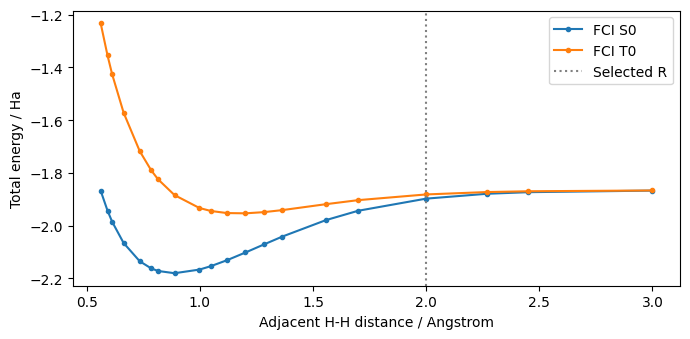

In [5]:
list_geometries()
fig,ax=plt.subplots(figsize=(7,3.5))
pec=SNAPSHOT_INDEX['geometries']
for key,label in [('energy_S0','FCI S0'),('energy_T','FCI T0')]:
    ax.plot([r['R'] for r in pec],[r[key]+r['enuc'] for r in pec],'o-',ms=3,label=label)
ax.axvline(float(MODEL['R']),color='gray',ls=':',label='Selected R')
ax.set(xlabel='Adjacent H-H distance / Angstrom',ylabel='Total energy / Ha');ax.legend()
plt.tight_layout();plt.show();plt.close(fig)

### 課題0：構造と厳密参照

Rを変えても、前の構造の準備回路と新しい構造の発展回路を混ぜてよいか。
厳密発展回路のCX数が未表示なら、費用が0と考えてよいか。

<details><summary>解答例</summary>

混ぜてはいけません。構造ごとにH・軌道・状態の振幅が対応します。この教材ではselect_geometryで一式を切り替えます。
厳密発展の密行列は基底ゲートへ分解していないため、CX数は未評価です。0ではありません。
実機用の費用比較には保存された近似発展を使います。

</details>

## 共通の分子・回路条件

直鎖H₄、選択した隣接距離R（既定2 Å）、STO-3G、全4電子・4空間軌道、**Boys局在化＋軌道順最適化**。
系8＋補助1 qubit、モード順α₀…α₃,β₀…β₃、補助q₈です。
S₀と最低三重項T₀のMₛ=0成分（コードT）を使います。Δt=0.1、t=LΔt、β=εt。
準備・発展とも同じ軌道の保存済み回路を内蔵し、符号付きFock順変換も発展回路に含みます。
S₀・Tの両枝に共通の準備Mと時間発展Mを、冒頭の設定セルで独立に選びます（既定6・16）。Mは回路の層数で、時間反復LやMPSのbond dimension χとは別です。
最適化は再実行しません。初期化セルはデータ・補助関数を含むため折り畳んでいます。

## 0．H₂からH₄へ：模型の大きさと計算する差

STO-3GのH₄では4空間軌道×2スピンで8スピン軌道です。
削減なしJWは8占有qubit、Fock空間は256次元です。4電子の空間は70次元、Nα=Nβ=2は36次元です。
補助q₈を加え、回路は9 qubitで動かします。

本冊は等間隔直鎖、選択した隣接距離Rで、Boys局在化と軌道順の最適化を施した軌道を使います。
H₂の正準軌道や別のH₄データの振幅・回路を混ぜず、**同じ軌道のH・準備・発展**を組み合わせます。
全軌道を活性に含めた同じ模型内の軌道回転はFCIエネルギーを変えませんが、配置振幅・Pauli係数・回路費用は変わります。
符号付きのFock順変換も保存発展回路に含まれています。普通のビットSWAPだけではフェルミオンの符号を表せません。

対象はS₀と最低三重項T₀のM_S=0成分です。Hは電子Hamiltonian、全エネルギーはE+E_nucです。
次セルで基準エネルギー、ギャップ、粒子数・スピンを確認します。

In [6]:
NA,NB,SPIN2=spin_operators()
print('State  total energy / Ha   Nalpha Nbeta  S^2')
for name,psi,key in [('S0',EXACT_STATES[0],'energy_S0'),('T',EXACT_STATES[1],'energy_T')]:
    energy=float(MODEL[key])
    np.testing.assert_allclose(H@psi,energy*psi,atol=1e-11)
    na,nb,ss=[float(np.vdot(psi,op@psi).real) for op in [NA,NB,SPIN2]]
    np.testing.assert_allclose([na,nb,ss],[2,2,0 if name=='S0' else 2],atol=1e-10)
    print(f'{name:4s} {energy+float(MODEL["enuc"]):18.10f} {na:6.1f} {nb:5.1f} {ss:4.1f}')
print('FCI gap / Ha:',GAP,'DT:',DT,'system dimension:',len(H))

State  total energy / Ha   Nalpha Nbeta  S^2
S0        -1.8977806460    2.0   2.0  0.0
T         -1.8818756881    2.0   2.0  2.0
FCI gap / Ha: 0.015904957916185403 DT: 0.1 system dimension: 256


### 課題1：大きさと対象を確認する

1. H₄が系8 qubitになるのは電子が8個だからか。
2. 本冊のS₀とT₀の差を、H₂のS₀とS₂の差と同じ値だと考えてよいか。

<details><summary>解答例</summary>

1. 電子は4個です。qubit数は8スピン軌道の占有を残すことから決まります。
2. 分子・構造・二つの状態が異なるので同じ値ではありません。R=2 Åの例の正のT₀−S₀差は約0.01590496 Haです。他構造では表示されたFCI差を使います。
状態・軌道・Hamiltonianを揃えた上で、その模型内の参照値と比較します。

</details>

## 1．厳密準備とTrotter発展は、どこが重くなるか

H₂の固有状態は二配置の重ね合わせで短く準備できました。
H₄では各状態を256成分の振幅として与え、多重化Ry回転で$P_k|0^8\rangle=|\psi_k\rangle$を作ります。
振幅から角度を直接求める**厳密な合成**で、状態探索やVQEではありません。
一般の実振幅準備で扱う係数や回転数はqubit数とともに指数的に増えます。

```text
既知のFCI振幅 ψ(q7,...,q0)
       ↓ 部分ノルムから角度を計算
上位ビットのRy → 条件付きRyの列 → 下位ビットのRy → Pk|0^8> = ψk
```

発展は演習3と同じ、$H=\sum_jc_jP_j$からPauli回転を並べる二次Trotterです。
Pauli項数は次セルで表示します（I項を含む）。一歩Δt=0.1を分割数sで近似します。
小さい係数を既定の相対許容誤差で落とさないよう、展開時はatol=10⁻¹⁴、rtol=0を指定し、Hへ戻ることを照合します。
長距離の構造では小さな係数も残し、構造を変えても同じHを使います。
Trotterは厳密なexp(−iHΔt)そのものではありません。分割数を増やすと誤差を減らせますが回路は長くなります。

費用を比較する際は、**個別状態の準備P₀**と、**二つの枝を作る9 qubitのA**を分けます。
同様に、発展一歩と、準備・逆準備・位相補正まで含む全BPDEも分けます。
次セルは同じ基底ゲート・全結合条件でこれらをコンパイルします。

In [7]:
BASIS=['rz','sx','x','cx']
COSTS={}
COMPILED_CIRCUITS={}

def record_cost(name,qc):
    if any(i.operation.name=='unitary' and i.operation.num_qubits==8 for i in qc.data):
        COSTS[name]=dict(qubits=qc.num_qubits,cx=None,depth=None)
        COMPILED_CIRCUITS[name]=qc
        print(name,': dense exact reference; native CX/depth not synthesized')
        return qc
    native=transpile(qc,basis_gates=BASIS,optimization_level=1,seed_transpiler=7)
    row=dict(qubits=qc.num_qubits,cx=int(native.count_ops().get('cx',0)),depth=native.depth())
    COSTS[name]=row
    COMPILED_CIRCUITS[name]=native
    print(f'{name:34s} qubits={row["qubits"]} CX={row["cx"]:5d} depth={row["depth"]:6d}')
    return native

EXACT_PREPS=[prepare_real(psi) for psi in EXACT_STATES]
pauli=SparsePauliOp.from_operator(Operator(H),atol=1e-14,rtol=0)
np.testing.assert_allclose(pauli.to_matrix(),H,atol=1e-12)
TROTTER_SLICES=1  # 1, 2, 4で一歩DTの費用を比較
qc_trotter=QuantumCircuit(8)
qc_trotter.append(PauliEvolutionGate(pauli,time=DT,
    synthesis=SuzukiTrotter(order=2,reps=TROTTER_SLICES)),range(8))
qc_trotter=qc_trotter.decompose()
for name,qc in [('Exact S0 preparation',EXACT_PREPS[0]),('Exact T preparation',EXACT_PREPS[1]),
                ('Exact coherent A',A_EXACT),('Trotter step',qc_trotter)]:
    record_cost(name,qc)
for name,qc,psi in zip(['S0','T'],EXACT_PREPS,EXACT_STATES):
    np.testing.assert_allclose(Statevector.from_instruction(qc).data,psi,atol=1e-11)
print('Pauli terms:',len(pauli),'Trotter slices:',TROTTER_SLICES,'time step:',DT)

Exact S0 preparation               qubits=8 CX=  254 depth=   990
Exact T preparation                qubits=8 CX=  254 depth=  1246
Exact coherent A                   qubits=9 CX=  510 depth=  2490
Trotter step                       qubits=8 CX= 2406 depth=  4566
Pauli terms: 361 Trotter slices: 1 time step: 0.1


### 課題2：費用表の読み方

1. 表のTrotter stepは厳密な時間発展か。
2. 個別S₀の準備とcoherent AのCX数が違う理由は何か。
3. TROTTER_SLICESを増やすこととLを増やすことは同じか。

<details><summary>解答例</summary>

1. 近似です。厳密準備とTrotter発展を組み合わせても「全て厳密」にはなりません。
2. Aは補助に応じてS₀/Tの両枝を作る回路なので、個別準備とは制御と回転の数が異なります。
3. 分割数は一歩DTの内部、Lは一歩の回路の反復です。前者は総時間DTを保ち、後者は総時間LDTを増やします。
既定の全結合条件では個別厳密準備は各254 CX、coherent Aは510 CXです。
Trotterの費用は表示されたPauli項数・分割数で確認します。係数を落とした別のHと混同しないことが必要です。

</details>

## 2．MPS/MPOから短い回路へ：表現と回路化を分ける

MPSは状態の振幅を、物理添字qᵢを持つ小さなテンソルの連鎖で表します。
$$\psi_{q_7\cdots q_0}=A^{[7]q_7}A^{[6]q_6}\cdots A^{[0]q_0}.$$
MPOは各サイトに出力・入力の二つの物理添字を持ち、演算子を同様に表します。
$$U_{q'_7\cdots q'_0,q_7\cdots q_0}=W^{[7]q'_7q_7}\cdots W^{[0]q'_0q_0}.$$
隣のテンソルをつなぐ内部添字の最大次元がbond dimensionです。
MPSのχ、回路の層数M、時間反復L、Trotter分割数sはそれぞれ別の量です。

```text
FCI状態 → χ=6のMPS目標 → 指定Mの2-qubitゲート列へフィット → 準備回路Pk
時間発展 → TrotterとMPO積・SVDによる参照MPO → 指定Mゲート列へフィット → 発展回路Uapp
```

テンソルが状態や演算子を正確に表せても、限られた層数の回路が同じ精度になるとは限りません。
特に、MPS/MPOの打切りと、回路へのフィットは別段階の近似です。
参照MPOは圧縮で非ユニタリになり得るため、その行列をそのまま測定回路として使いません。
測定には保存された**ユニタリなゲート列**を使います。

本冊の保存計算では、χ=6 MPSは両状態を数値精度で保持しています。
準備回路は状態fidelityへのフィット、発展回路は参照MPOへの演算子誤差へのフィットです。
発展回路は二次Trotter100分割とSVD cutoff=10⁻¹⁸から得たMPOを目標とする有限予算の保存結果で、完全収束や大域最適解は主張していません。
参照MPOを厳密なexp(−iHDT)と同一視せず、最終的なfidelityと信号は共通のHから得たU_exactで再評価します。
このNotebookでは最適化を再実行せず、実際の保存回路を検証します。

保存回路は隣接2-qubitゲートを交互に並べる層構造です。1個のGは1個の2-qubitユニタリで、CX 1個とは限りません。

```text
層1: G(0,1)  G(2,3)  G(4,5)  G(6,7)
層2:     G(1,2)  G(3,4)  G(5,6)
層3: G(0,1)  G(2,3)  G(4,5)  G(6,7) ...
```

準備・発展ともM層には交互の4・3ブロックがあります（既定M6は21、M16は56ブロック）。
M4/M8の枝回路は小さい成分も保つ厳密な局所分解で合成しています。CX数はMだけで決めず、次の費用表で確認します。
発展のゲート列はinterleavedスピン順で作られており、準備のblocked順へ接続するときの変換も含めて費用を数えます。

In [8]:
FIT_INFO={'chi': 6, 'mpo_microsteps': 100, 'mpo_cutoff': 1e-18, 'refinement_cap': 10000, 'full_convergence_claimed': False}

print('Preparation M, chi:',SELECTED_PREP_M,PREP_INFO['reports']['S0']['chi'],'evolution M:',SELECTED_EVOLUTION_M)
print('MPO target microsteps/cutoff:',FIT_INFO['mpo_microsteps'],FIT_INFO['mpo_cutoff'])
print('Evolution fit iteration cap:',EVOLUTION_INFO['report']['refinement_cap'],
      'full convergence claimed:',EVOLUTION_INFO['report']['full_convergence_claimed'])

Preparation M, chi: 6 6 evolution M: 16
MPO target microsteps/cutoff: 100 1e-18
Evolution fit iteration cap: 10000 full convergence claimed: False


## 3．state fidelityとoperator fidelityは、何を比べるか

状態は一つのベクトルの重なり、演算子は全256次元での一致を評価します。
$$F_{\rm state}^{(k)}=|\langle\psi_k^{\rm FCI}|P_k^{\rm app}|0^8\rangle|^2,\qquad
F_{\rm op}=\left|\frac{\mathrm{Tr}(U_{\rm exact}^\dagger U_{\rm app})}{256}\right|^2.$$
state fidelityはS₀とTを別々に、operator fidelityは一歩DT=0.1に対して計算します。
F_opは全Fock空間の指標で、目的の二状態だけの位相差誤差ではありません。
F_op=1なら大域位相を除いて一致しますが、一般に1に近いだけではギャップの精度を保証しません。

次セルでは**MPS目標のfidelity**と**実際の回路状態のfidelity**を並べます。
厳密準備を選んだ場合はMPSを経ず、目標欄にはFCIそのものへのfidelity=1を表示します。
準備回路のNα,Nβは2を保ちますが、S²を厳密に固定する最適化ではないことも確認します。

In [9]:
STATE_FIDELITIES={}
print('State  target fidelity      circuit fidelity      energy error/Ha    <S^2>')
for name,exact,approx,key in zip(['S0','T'],EXACT_STATES,APPROX_STATES,['energy_S0','energy_T']):
    fidelity=float(abs(np.vdot(exact,approx))**2)
    STATE_FIDELITIES[name]=fidelity
    target_fid=SELECTED_RESULTS['fidelities'][name+'_MPS']
    energy_error=float(np.vdot(approx,H@approx).real-float(MODEL[key]))
    spin=float(np.vdot(approx,SPIN2@approx).real)
    np.testing.assert_allclose([np.vdot(approx,NA@approx),np.vdot(approx,NB@approx)],[2,2],atol=1e-10)
    np.testing.assert_allclose(fidelity,SELECTED_RESULTS['fidelities'][name],atol=1e-10)
    print(f'{name:4s} {target_fid:.14f} {fidelity:20.12f} {energy_error:18.8f} {spin:10.6f}')
OPERATOR_FIDELITY=float(abs(np.trace(U_EXACT.conj().T@U_APPROX)/256)**2)
print('One-step operator fidelity:',OPERATOR_FIDELITY)
print('One-step relative operator error:',np.linalg.norm(U_APPROX-U_EXACT)/np.linalg.norm(U_EXACT))
np.testing.assert_allclose(U_APPROX.conj().T@U_APPROX,np.eye(256),atol=1e-10)

State  target fidelity      circuit fidelity      energy error/Ha    <S^2>
S0   1.00000000000000       0.938599805718         0.00878435   0.010913
T    1.00000000000000       0.999563980340         0.00032256   1.999567
One-step operator fidelity: 0.9999998582234327
One-step relative operator error: 0.0003765323017219145


### 課題3：テンソルと回路の精度を混同しない

1. χ=6 MPSのfidelityがほぼ1なら、M6準備回路もほぼ1といえるか。
2. operator fidelityがS₀のstate fidelityより高ければ、BPDEのギャップ誤差も小さいといえるか。
3. 準備回路がユニタリで、粒子数が正しければ、参照S₀そのものを作れているか。

<details><summary>解答例</summary>

1. いえません。MPSから限られた層数の回路へフィットする段階が別にあります。
既定R=2 Å・M6/M16の例ではMPS目標は両方ほぼ1ですが、回路はS₀≈0.93860、T≈0.999564です。
2. 指標の対象が違うため、その数値だけでは順位付けできません。R=2 Å・M16のF_op≈0.999999858でも、目的の相対位相を別に調べます。
3. ユニタリ性と粒子数は必要な検証ですが、特定の固有状態への一致を保証しません。重なり・S²・エネルギーなどを確認します。

</details>

## 4．近似回路の費用：単独準備、枝制御、逆準備を数える

個別の保存準備P₀、P_Tは、配置準備を含めて$P_k|0^8\rangle=|\widetilde\psi_k\rangle$を作ります。
BPDE用には$A=\mathrm{diag}(P_0,P_T)(H_a\otimes I)$を実装し、
$$(|0\rangle_a|\widetilde\psi_0\rangle+|1\rangle_a|\widetilde\psi_T\rangle)/\sqrt2$$
を準備します。同じ入力配置とゲート配置を共有し、対応する局所ゲートG₀の後へ
補助1で制御した$G_TG_0^\dagger$を置くことで、二つの枝を選びます。
実際のAの逆を逆準備に使い、近似状態を作った後だけ厳密な逆回路へ取り替えることはしません。

```text
a=q8: |0> ──┌─────┐────────P(εt)──┌─────┐──M──┐
            │  A  │               │ A†  │     ├─ 全9ビット0を数える
s=q0..7: ───└─────┘──[Uapp]^L──────└─────┘──M──┘
```

既定R=2 Åの発展M16の基底ゲート列だけは168 CXですが、モード順変換を前後に含めると216 CXです。
次セルは実際に本冊で使う部品を同じ条件で再コンパイルし、**同じ役割同士**を比較します。
最後の表では、厳密準備＋Trotterと、指定Mの準備＋発展の全回路を比べます。
前者の発展もTrotter近似で、完全に厳密なexp(−iHt)回路の資源とは区別します。

In [10]:
for name,qc in [('Approx S0 preparation',load_circuit_asset('S0')),
                ('Approx T preparation',load_circuit_asset('T')),
                ('Approx coherent A',A_APPROX),('Approx A inverse',A_APPROX.inverse()),
                ('Approx evolution with conversion',EVOLUTION_APPROX)]:
    record_cost(name,qc)
expected_pair=np.r_[APPROX_STATES[0],APPROX_STATES[1]]/np.sqrt(2)
np.testing.assert_allclose(Statevector.from_instruction(A_APPROX).data,expected_pair,atol=1e-10)
exact_prep_trotter=QuantumCircuit(9)
exact_prep_trotter.compose(A_EXACT,inplace=True)
exact_prep_trotter.compose(qc_trotter,range(8),inplace=True)
exact_prep_trotter.p(GAP*DT,8)
exact_prep_trotter.compose(A_EXACT.inverse(),inplace=True)
record_cost('Exact prep + Trotter L=1',exact_prep_trotter)
native_both=record_cost(f'M{SELECTED_PREP_M} prep + M{SELECTED_EVOLUTION_M} evolution L=1',experiment_circuit(1,GAP))

Approx S0 preparation              qubits=8 CX=   60 depth=    60
Approx T preparation               qubits=8 CX=   60 depth=    62
Approx coherent A                  qubits=9 CX=  258 depth=   378
Approx A inverse                   qubits=9 CX=  258 depth=   394
Approx evolution with conversion   qubits=8 CX=  216 depth=   353
Exact prep + Trotter L=1           qubits=9 CX= 3426 depth=  9546
M6 prep + M16 evolution L=1        qubits=9 CX=  732 depth=  1095


### 課題4：同じ条件で費用を比較する

1. 単独のM6準備60 CXを、そのままBPDE全体の費用と呼べるか。
2. M16が168 CXなのに、本冊の発展ブロックが216 CXになる理由は何か。
3. Lを増やすと、準備もL回になるか。

<details><summary>解答例</summary>

1. 呼べません。枝を作るcoherent A、逆準備、発展、位相補正が必要です。
既定R=2 Å・M6/M16ではAとA†は各258 CX、変換込みの発展は216 CXで、L=1の全体は732 CXです。
2. 準備と発展のモード順を合わせる符号付き変換の費用を含めるためです。
3. 各ショットの準備と逆準備は1回ずつ、発展だけがL回です。直列計数はCX(A)+CX(A†)+L×CX(Uapp)です。既定6/16では516+216L CXです。
全体最適化や実機ルーティングにより実際の値は変わるので、これは費用の見積もりです。

</details>

## 5．四つの条件で、L=1の全0曲線を比較する

近似の原因を切り分けるため、次の4条件を同じH・時間・読出しで比べます。

| CASE | 準備する状態 | 一歩の発展 |
|---|---|---|
| `exact` | FCIの厳密S₀/T | exp(−iHDT) |
| `prep_only` | 指定Mの両状態 | exp(−iHDT) |
| `evolution_only` | FCIの厳密S₀/T | 指定Mの保存ユニタリ |
| `both` | 指定Mの両状態 | 指定Mの保存ユニタリ |

$$a_k=\langle\psi_k|U^L|\psi_k\rangle,\quad
P(0^9)=\tfrac14|a_0+e^{i\varepsilon t}a_T|^2.$$
固定したLでは$a_0,a_T$が定数なので、候補εに対する曲線は
$$P(\varepsilon)=\frac{|a_0|^2+|a_T|^2}{4}
+\frac12\mathrm{Re}[e^{i\varepsilon t}a_0^*a_T]$$
という一本の余弦です。近似状態が多くの固有成分を含んでも、この**固定Lでのε掃引**が多周波数になるわけではありません。
影響は高さ・位相に表れ、Lを変えたときの$a_k(L)$には複数成分の時間依存が現れ得ます。

次セルの左図は周期を見る広い範囲、中央は真値付近、右は厳密信号との差です。
FCIギャップを中心に拡大しているのは回路の診断のためで、未知の差を推定した結果ではありません。

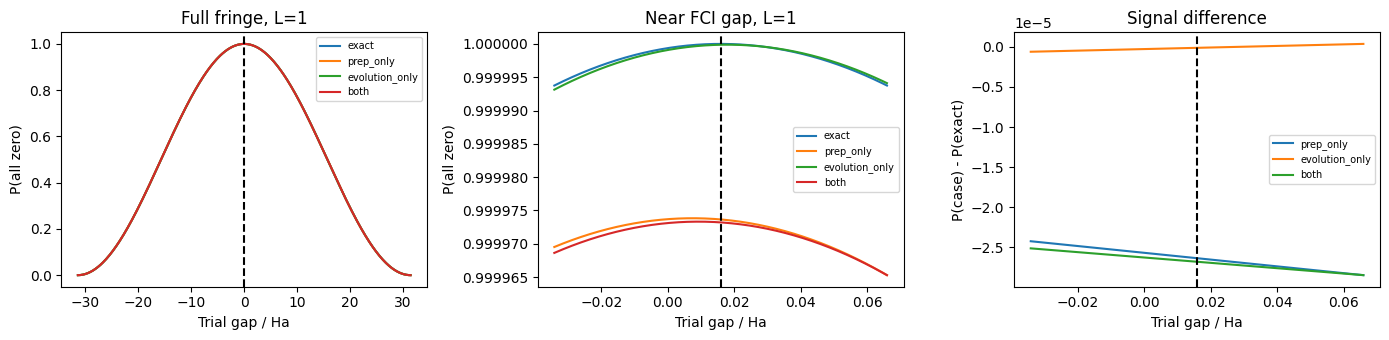

In [11]:
wide=np.linspace(GAP-np.pi/DT,GAP+np.pi/DT,401)
zoom=np.linspace(GAP-.05,GAP+.05,301)
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
for case in CASES:
    axes[0].plot(wide,probability(case,1,wide),label=case)
    axes[1].plot(zoom,probability(case,1,zoom),label=case)
    if case!='exact':axes[2].plot(zoom,probability(case,1,zoom)-probability('exact',1,zoom),label=case)
for ax in axes:
    ax.axvline(GAP,color='black',ls='--');ax.set_xlabel('Trial gap / Ha');ax.legend(fontsize=7)
axes[0].set(ylabel='P(all zero)',title='Full fringe, L=1')
axes[1].set(ylabel='P(all zero)',title='Near FCI gap, L=1')
axes[1].ticklabel_format(axis='y',style='plain',useOffset=False)
axes[2].set(ylabel='P(case) - P(exact)',title='Signal difference')
plt.tight_layout();plt.show();plt.close(fig)

### 5.1．fidelityと、短時間の高さ・位相を数値で結ぶ

各枝の自己相関の絶対値が1に近ければ、全0信号の最大値も1に近くなります。
しかし自己相関$|\langle\psi|U|\psi\rangle|^2$と、参照固有状態とのfidelityは別の重なりです。
厳密Hでの短時間なら$|\langle\psi|e^{-iHt}|\psi\rangle|^2=1-\mathrm{Var}_{\psi}(H)t^2+O(t^4)$なので、
固有状態との重なりが十分でなくても短時間ではほぼ元に戻り得ます。

$z=a_0^*a_T$とすると、ピーク位置は$\varepsilon_{\rm peak}=-\arg(z)/t$（周期$2\pi/t$）で、
最大値は$(|a_0|+|a_T|)^2/4$です。
次セルはL=1の両者を表示します。ピークは選んだ周期の**一回の干渉位相**であり、Hamiltonianの固有値やBayesian推定値ではありません。

In [12]:
L1_METRICS={}
print('Case             Pmax          peak/Ha       peak-FCI/Ha    |a0|^2      |aT|^2')
for case,(states,u) in CASES.items():
    a0,at=[np.vdot(psi,u@psi) for psi in states]
    z=a0.conjugate()*at
    peak=-float(np.angle(z))/DT
    pmax=float((abs(a0)+abs(at))**2/4)
    L1_METRICS[case]=dict(peak=peak,pmax=pmax,bias=peak-GAP,
                        ground_survival=float(abs(a0)**2),triplet_survival=float(abs(at)**2))
    np.testing.assert_allclose(probability(case,1,peak),pmax,atol=1e-10)
    print(f'{case:15s} {pmax:.10f} {peak:13.9f} {peak-GAP:+14.9f} {abs(a0)**2:11.8f} {abs(at)**2:11.8f}')
np.testing.assert_allclose(L1_METRICS['both']['peak'],SELECTED_RESULTS['fringe']['apparent_gap'],atol=1e-10)
np.testing.assert_allclose(L1_METRICS['both']['pmax'],SELECTED_RESULTS['fringe']['Pmax'],atol=1e-10)

Case             Pmax          peak/Ha       peak-FCI/Ha    |a0|^2      |aT|^2
exact           1.0000000000   0.015904958   +0.000000000  1.00000000  1.00000000
prep_only       0.9999738327   0.007449172   -0.008455785  0.99995012  0.99999754
evolution_only  0.9999998822   0.017861839   +0.001956881  0.99999986  0.99999990
both            0.9999733219   0.009228877   -0.006676081  0.99994926  0.99999738


In [13]:
# 同じ回路の行列確率と、全9 qubit状態ベクトルの全0確率を照合。
for eps in [GAP, GAP+.25]:
    actual=Statevector.from_instruction(experiment_circuit(1,eps)).probabilities()[0]
    np.testing.assert_allclose(actual,probability('both',1,eps),atol=1e-10)
np.testing.assert_allclose(probability('exact',3,np.array([GAP,GAP+.1])),
    (1+np.cos(np.array([0,.1])*3*DT))/2,atol=1e-10)
assert GAP>0
np.testing.assert_allclose(GAP,float(MODEL['energy_T']-MODEL['energy_S0']),atol=1e-12)
print('Circuit / amplitude / exact cosine checks passed')

Circuit / amplitude / exact cosine checks passed


### 課題5：高い信号が意味すること

1. 既定R=2 Å・M6/M16でS₀のstate fidelity≈0.9386なのに、L=1のPmax≈0.99997となるのは矛盾か。
2. `both`のL=1のピークは、FCIギャップと一致しているか。
3. operator fidelityが1に近いことと、ギャップの相対誤差が小さいことは同じか。

<details><summary>解答例</summary>

1. 矛盾しません。前者は参照固有状態との重なり、後者は短時間発展後に近似準備状態へ戻る干渉信号です。
短時間では異なる固有成分もまだ大きく位相が離れていないことがあります。
2. 既定R=2 Å・M6/M16ではFCI≈0.01590496 Haに対し、bothのピークは約0.00922888 Ha、ずれは約−0.00667608 Haです。
高いPmaxだけから「正しいエネルギー差が得られた」とは判断できません。
3. 同じではありません。小さなギャップでは、小さな位相の偏りも大きな相対誤差になり得ます。
演算子・準備・信号・推定をそれぞれ確認します。

</details>

### 5.2．Mを変えて、精度・費用・L=1曲線を比較する

準備M=4・6・8 × 発展M=8・16・32の9通りを、同じH・Δt=0.1・CASE=bothで比べます。
この対照はMODEにかかわらず**shot noiseなし**で、実機へ送信しません。
表のCXはCX(A)+CX(A†)+CX(Uapp)というL=1のブロック直列見積もりです。
全結合条件で、全体最適化・実機配置の費用は含みません。
F_opがほぼ1なので、図では1−F_opを対数軸で示します。
曲線の上段はFCI近傍の全0確率、下段は同じ探索点での厳密信号との差です。
L=1でのピークずれは一回の干渉位相のずれで、演習5の反復推定のずれとは別です。

比較後は冒頭で選んだMへ戻します。以降の主実験の設定は変えません。

R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=8; serial CX = 348 + 132 L
R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=16; serial CX = 348 + 216 L
R_2p00000000: PREP_M=4 (S0/T), EVOLUTION_M=32; serial CX = 348 + 384 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=8; serial CX = 516 + 132 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=32; serial CX = 516 + 384 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=8; serial CX = 688 + 132 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=16; serial CX = 688 + 216 L
R_2p00000000: PREP_M=8 (S0/T), EVOLUTION_M=32; serial CX = 688 + 384 L
R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L


| 準備M | 発展M | F_state(S0) | F_state(T0) | F_op | CX(L=1) | Pmax(L=1) | peak−FCI / Ha |
|---|---|---|---|---|---|---|---|
| 4 | 8 | 0.74723687 | 0.53501181 | 0.999849275337 | 480 | 0.99896751 | +0.09194811 |
| 4 | 16 | 0.74723687 | 0.53501181 | 0.999999858223 | 564 | 0.99920306 | +0.08786794 |
| 4 | 32 | 0.74723687 | 0.53501181 | 0.999999998019 | 732 | 0.99920253 | +0.08566280 |
| 6 | 8 | 0.93859981 | 0.99956398 | 0.999849275337 | 648 | 0.99993490 | -0.06536991 |
| 6 | 16 | 0.93859981 | 0.99956398 | 0.999999858223 | 732 | 0.99997332 | -0.00667608 |
| 6 | 32 | 0.93859981 | 0.99956398 | 0.999999998019 | 900 | 0.99997379 | -0.00850272 |
| 8 | 8 | 0.99945917 | 0.99999414 | 0.999849275337 | 820 | 0.99997203 | -0.03813153 |
| 8 | 16 | 0.99945917 | 0.99999414 | 0.999999858223 | 904 | 0.99999770 | +0.00150742 |
| 8 | 32 | 0.99945917 | 0.99999414 | 0.999999998019 | 1072 | 0.99999785 | -0.00046244 |

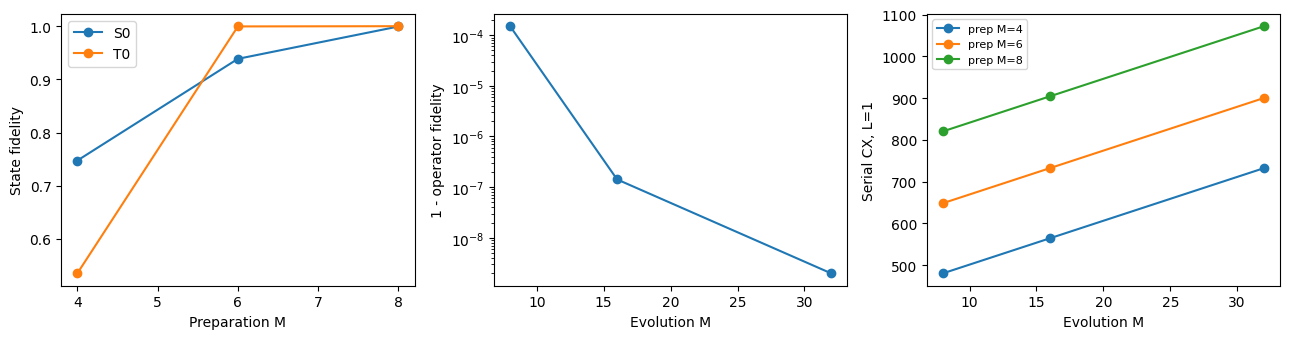

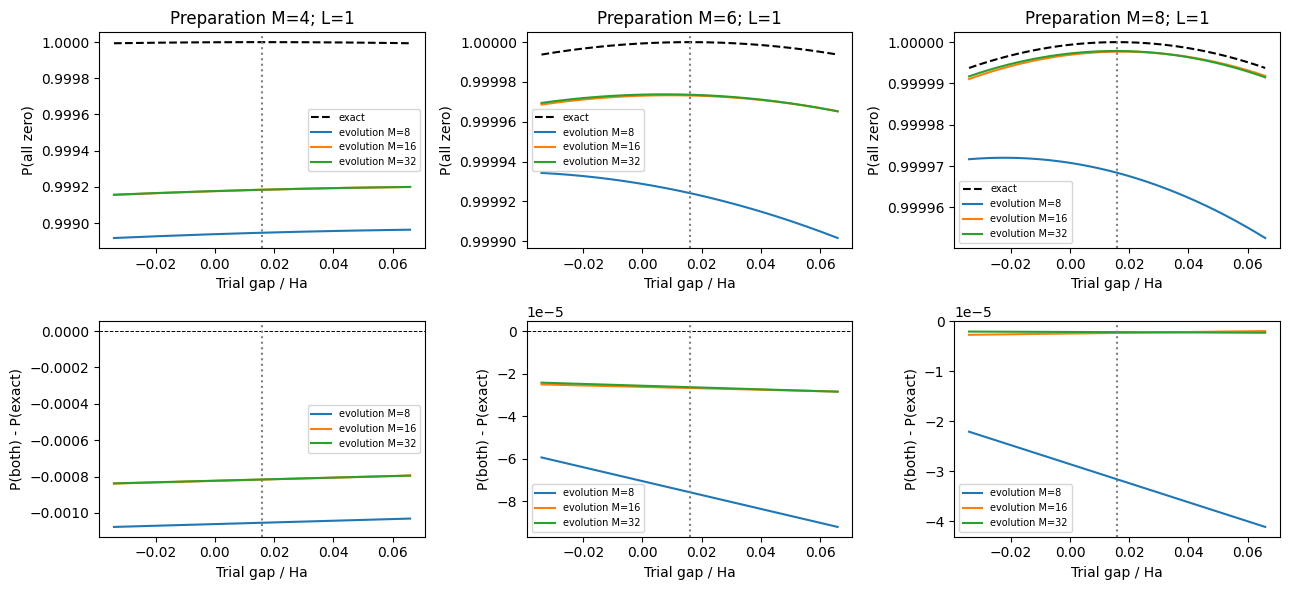

In [14]:
from IPython.display import Markdown, display

def assess_saved_m():
    selected=(SELECTED_PREP_M,SELECTED_EVOLUTION_M)
    rows=[]
    eps=np.linspace(GAP-.05,GAP+.05,301)
    exact_curve=probability('exact',1,eps)
    try:
        for pm in AVAILABLE_PREP_M:
            for em in AVAILABLE_EVOLUTION_M:
                select_circuits(pm,em)
                rows.append(dict(prep_m=pm,evolution_m=em,
                    state_S0=SELECTED_RESULTS['fidelities']['S0'],
                    state_T=SELECTED_RESULTS['fidelities']['T'],
                    operator_fidelity=EVOLUTION_INFO['operator_fidelity'],
                    cx_L1=SERIAL_CX['preparation']+SERIAL_CX['evolution'],
                    pmax=SELECTED_RESULTS['fringe']['Pmax'],
                    peak_error=SELECTED_RESULTS['fringe']['apparent_gap']-GAP,
                    curve=probability('both',1,eps)))
    finally:
        select_circuits(*selected)
    return rows,eps,exact_curve

M_ASSESSMENT,M_SCAN,M_EXACT_CURVE=assess_saved_m()
header='| 準備M | 発展M | F_state(S0) | F_state(T0) | F_op | CX(L=1) | Pmax(L=1) | peak−FCI / Ha |\n|---|---|---|---|---|---|---|---|'
lines=[f"| {r['prep_m']} | {r['evolution_m']} | {r['state_S0']:.8f} | {r['state_T']:.8f} | {r['operator_fidelity']:.12f} | {r['cx_L1']} | {r['pmax']:.8f} | {r['peak_error']:+.8f} |" for r in M_ASSESSMENT]
display(Markdown(header+'\n'+'\n'.join(lines)))
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
prep_rows=[r for r in M_ASSESSMENT if r['evolution_m']==16]
for key,label in [('state_S0','S0'),('state_T','T0')]:
    axes[0].plot([r['prep_m'] for r in prep_rows],[r[key] for r in prep_rows],'o-',label=label)
axes[0].set(xlabel='Preparation M',ylabel='State fidelity');axes[0].legend()
evo_rows=[r for r in M_ASSESSMENT if r['prep_m']==6]
axes[1].semilogy([r['evolution_m'] for r in evo_rows],
    [1-r['operator_fidelity'] for r in evo_rows],'o-')
axes[1].set(xlabel='Evolution M',ylabel='1 - operator fidelity')
for pm in AVAILABLE_PREP_M:
    rows=[r for r in M_ASSESSMENT if r['prep_m']==pm]
    axes[2].plot([r['evolution_m'] for r in rows],[r['cx_L1'] for r in rows],'o-',label=f'prep M={pm}')
axes[2].set(xlabel='Evolution M',ylabel='Serial CX, L=1');axes[2].legend(fontsize=8)
plt.tight_layout();plt.show();plt.close(fig)
fig,axes=plt.subplots(2,3,figsize=(13,6))
for j,pm in enumerate(AVAILABLE_PREP_M):
    axes[0,j].plot(M_SCAN,M_EXACT_CURVE,'k--',label='exact')
    for r in [r for r in M_ASSESSMENT if r['prep_m']==pm]:
        label=f"evolution M={r['evolution_m']}"
        axes[0,j].plot(M_SCAN,r['curve'],label=label)
        axes[1,j].plot(M_SCAN,r['curve']-M_EXACT_CURVE,label=label)
    axes[0,j].set(title=f'Preparation M={pm}; L=1',ylabel='P(all zero)')
    axes[0,j].ticklabel_format(axis='y',useOffset=False)
    axes[1,j].axhline(0,color='black',ls='--',lw=.7)
    axes[1,j].set(ylabel='P(both) - P(exact)')
    for ax in axes[:,j]:
        ax.axvline(GAP,color='gray',ls=':');ax.set_xlabel('Trial gap / Ha');ax.legend(fontsize=7)
plt.tight_layout();plt.show();plt.close(fig)

### 課題5補足：Mの比較表を読む

Mを増やしてfidelityが上がれば、L=1のピークずれも必ず小さくなるか。
また、表のCX(L=1)をそのまま次冊の全ラウンドの費用と呼べるか。

<details><summary>解答例</summary>

どちらもいえません。fidelityは状態の重なり／全空間の演算子の一致で、目的の相対位相そのものではありません。
準備と発展の誤差は相殺する場合もあり、表のpeak−FCIと曲線を直接確認します。
state fidelityは準備Mだけ、operator fidelityは発展Mだけに依存しますが、信号は両方に依存します。
次冊では各ラウンドのLに合わせ、CX(A)+CX(A†)+L×CX(Uapp)を使います。
さらに探索点数と各点のshotsを掛ける必要があり、実機配置や待ち時間の費用も別です。

</details>

## 6．測定モードを選ぶ：CASEとMODEは別の設定

CASEは「どの状態と発展を使うか」、MODEは「その回路をどう測るか」です。

| 設定例 | 得る値 | 含まれる誤差 |
|---|---|---|
| CASE=exact, MODE=exact | 厳密準備・厳密発展の確率 | この模型内の参照 |
| CASE=both, MODE=exact | 選択したMの回路の厳密確率 | 指定部品の近似、shot noiseなし |
| CASE=both, MODE=shots | 二項模擬測定の全0頻度 | 指定部品の近似とshot noise（実機ノイズなし） |
| CASE=both, MODE=ibm | 実機の全0頻度 | 回路近似、shots、実機での影響 |

MODE=shotsでは$n_{0^9}\sim\mathrm{Binomial}(R,P)$、表示値は$n_{0^9}/R$です。
各探索点にSHOTS回を使うので、9点なら合計9×SHOTS回です。SEEDは模擬測定の再現性を決め、実機の乱数は制御しません。
MODE=exactではSHOTSを変えても結果は変わりません。SHOTSを増やしても回路近似の偏りは消えません。

**操作手順：** 次の設定セルのMODE・CASE・SHOTS・SEEDを変更したら、その設定セルから下を再実行します。
これによりmeterと乱数を作り直します。測定セルだけを繰り返す場合は、同じmeterの乱数系列の続きを使います。
初めはMODE=exact・CASE=both、その後MODE=shotsへ進めてください。

### 実機モードの使い方

冒頭の接続準備を実行してから、MODE=`ibm`、CASE=`both`へ変更します。
CRN・backend名・認証は引き継ぎます。接続準備をスキップした場合は先に戻って実行してください。
`hardware_preview(backend,L=...)`で接続制約を含む回路費用を確認してから、
RUN_HARDWAREをTrueにして設定セル以降を実行します。
ジョブIDは送信直後に`outputs/ibm_jobs/`へ保存し、同条件の再実行では再投入せず結果を回収します。
Colab切断に備えて、このフォルダをDrive等へ保存してください。フォルダを失うと自動復旧できません。
未確定の送信マーカーが残った場合はIBM側のジョブを確認してから復旧します。
実機は認証・利用枠・待ち時間が必要です。この教材作成時には送信していません。

[IBM Sampler入出力](https://eu-de.quantum.cloud.ibm.com/docs/en/guides/sampler-input-output)

### 6.1．実機モードの実行順

1. 冒頭の接続準備を実行し、MODE=ibm、CASE=bothへ変更する。BACKEND_NAMEとINSTANCEは接続準備の値を引き継ぐ。
2. RUN_HARDWARE=Falseで設定セルを実行し、L=1の配置後回路の費用を確認する。この状態では測定をスキップする。
3. 送信する場合はRUN_HARDWARE=Trueへ変更し、設定セルと次の測定セルを再実行する。
4. ジョブIDとcountsを保存し、結果を回収する。同じ条件の再実行は保存結果を使う。

実機では選択したMの実回路を使うためCASE=bothに限定します。
MODE=ibmへ変更しても、CASEをexactのまま残さないようにします。
MAX_HARDWARE_Lは発展反復の上限であり、QPU使用量や信号を保証する値ではありません。
実機接続制約を含む2量子ビット操作数は、全結合のCX数と区別してください。

In [15]:
MODE = 'exact'     # 'exact', 'shots', 'ibm'
CASE = 'both'      # 'exact', 'prep_only', 'evolution_only', 'both'; ibmはbothのみ
SHOTS = 1024       # 各探索点のshots。MODE='exact'では使わない
SEED = 42
BACKEND_NAME = '' or globals().get('IBM_BACKEND_NAME', '')  # 冒頭の選択を引き継ぐ
INSTANCE = '' or globals().get('IBM_INSTANCE', '')  # 冒頭のCRNを引き継ぐ
RUN_HARDWARE = False  # 実機の費用を確認後、送信する場合にTrue
MAX_HARDWARE_L = 8    # 実機の反復上限。増やす前に回路費用を確認する
service = backend = None
if MODE == 'ibm':
    if SELECTED_EVOLUTION_M == 'exact':
        raise ValueError('厳密発展の密行列回路はシミュレーション参照です。実機にはEVOLUTION_M=8/16/32を選びます')
    if CASE != 'both':
        raise ValueError("MODE='ibm'ではCASE='both'を選んでください（選択した実回路）")
    if not BACKEND_NAME:
        raise ValueError('BACKEND_NAMEを設定してください')
    service, backend = connect_ibm(BACKEND_NAME, INSTANCE)
    hardware_preview(backend, L=1)  # コンパイルのみ。送信しない
meter = Measurement(MODE, SHOTS, SEED, service, backend, RUN_HARDWARE, MAX_HARDWARE_L)
MEASUREMENT_READY = MODE != 'ibm' or RUN_HARDWARE
print('mode:', MODE, 'case:', CASE, 'FCI gap / Ha:', GAP)
if not MEASUREMENT_READY:
    print('Preview only: inspect costs, set RUN_HARDWARE=True, then rerun this setting cell and following cells.')

mode: exact case: both FCI gap / Ha: 0.015904957916185403


### 6.2．同じL=1曲線を9点で測る

次セルはL=1固定、広い1周期の9探索点です。線は選んだ回路の理想確率、点はMODEで選んだ測定値です。
9点から細かいピーク位置を精密推定するのではなく、信号が残るか、測定頻度がどう変わるかを診断します。
FCIギャップを中心にするのはこの検証用の既知の模型だからです。
実機モードでは9回路を1ジョブで送り、待ち時間中もジョブIDを保持します。

Trial gap / Ha    observed probability
    -31.400022            0.00000011
    -23.546040            0.14667881
    -15.692058            0.50032046
     -7.838077            0.85376657
      0.015905            0.99997321
      7.869887            0.85329451
     15.723868            0.49965287
     23.577850            0.14620675
     31.431831            0.00000011
Source: exact_probabilities


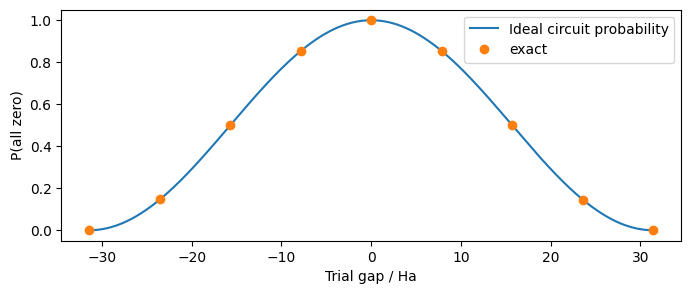

In [16]:
if MEASUREMENT_READY:
    L=1
    trial=np.linspace(GAP-np.pi/DT,GAP+np.pi/DT,9)
    measured=meter.measure(CASE,L,trial,'exercise4_L1')
    fig,ax=plt.subplots(figsize=(8,3))
    dense_trial=np.linspace(trial[0],trial[-1],401)
    ax.plot(dense_trial,probability(CASE,L,dense_trial),label='Ideal circuit probability')
    ax.plot(trial,measured,'o',label=MODE)
    ax.set(xlabel='Trial gap / Ha',ylabel='P(all zero)');ax.legend();plt.show();plt.close(fig)
    print('Trial gap / Ha    observed probability')
    for eps,p in zip(trial,measured):print(f'{eps:14.6f} {p:21.8f}')
    print('Source:',meter.records[-1]['source'])
    meter.save('outputs/exercise4_measurements.json')
else:
    print('Preview only; no measurement was submitted.')

### 課題6：モード切替と測定回数

1. MODE=exactのままSHOTSを128→8192へ変えると、何が変わるか。
2. MODE=shotsで同じ変更をすると、何が変わるか。
3. MODE=ibm、RUN_HARDWARE=Falseでは送信されるか。
4. 同じ保存先で同条件のIBM測定を再実行すると、新しいショットが追加されるか。

<details><summary>解答例</summary>

1. SHOTSを使わないので確率は変わりません。指定部品が近似なら回路近似は残っています。
2. 各探索点の頻度の標準偏差√[P(1−P)/SHOTS]が減ります。9点の総shotsは1152から73728へ増えます。
   実機ノイズを加えたシミュレーションにはならず、回路近似の偏りも残ります。
3. 設定セルは接続・コンパイルのプレビューを行いますが、測定セルは送信せずスキップします。
4. 同じ設定・保存先なら既存ジョブ／countsを再利用します。独立した再測定は別の保存先を指定し、元の記録を保持します。

</details>

## 7．演習5への接続：L=1の診断から反復推定へ

本冊の4条件比較とfidelity評価は、測定へ渡す回路を理解するための診断です。
次冊では**同じH、同じMの選択回路、全0確率、MODE/CASEの意味**を使い、測定後の知識からLと探索点を更新します。

```text
本冊: L=1固定 → 全0曲線・fidelity・費用を診断
次冊: 初期事前 → Lと探索点を選ぶ → 測定 → 事後 → 次の事前 → 繰り返す
```

本冊の9点を次冊の初期事前へ自動的に変換するわけではありません。次冊は独立した初期事前から開始します。
まず次冊のCASE=exact・MODE=exactで更新手順を見て、CASE=bothへ切り替えて本冊と同じ近似回路へ戻ります。
比較では初期事前・SHOTS・SEEDなどを揃えます。各Notebookは独立して設定セルを実行してください。

演習5のGaussian更新は、確率曲線をGaussianにフィットし、事前Gaussianと掛け合わせる著者コードの近似手順です。
演習1・2の二項尤度によるグリッド更新とは異なります。分布が狭くなることと、FCIとの差が小さくなることを別々に見ます。
実機ではL増加で発展回路が長くなります。次のLの費用をpreviewし、上限までの結果でも考察します。

### 課題7：次冊で確認すべきこと

1. 本冊でL=1のピークが高ければ、次冊の推定も正しいギャップへ収束すると断定できるか。
2. 次冊のCASE=exactとCASE=bothの比較で、何を揃えるべきか。
3. L=1の全0確率と、次冊の事後分布は同じ量か。

### 解答例（課題7：演習5への接続）

1. **断定できません。** 短時間の高さは正しい固有位相の保証ではありません。長時間での近似位相、混入成分、推定モデルも確認します。
2. 初期事前、測定方式、shots、seed、探索点数などを揃え、回路近似の有無を変えます。
   反復中のLや探索点は過去の測定に依存するため、同じ初期条件でも途中から異なり得ます。
3. **異なる量です。** 全0確率は回路から予測する測定事象の確率、事後分布は測定後の未知ギャップについての知識を表します。
